# Lab 05 — HOG-Based Industrial Defect Detection & Classification

**Pipeline:** `Image → Preprocessing → HOG Feature Extraction → ML Classifier → ACCEPT / REJECT`

**Dataset:** NEU Surface Defect Database (NEU-DET), Kaggle split by *sovitrath* (train / valid, Pascal-VOC boxes).

### A design decision you must understand before running this
NEU-DET contains **six defect classes and no "normal" class** — every image has at least one defect. A naive
"binary" split (e.g. calling one defect class *normal*) would be scientifically wrong. Instead, this notebook uses the
bounding-box annotations to build a proper binary dataset at **patch level**:

| Class | How patches are obtained |
|---|---|
| **1 — DEFECTIVE** | 64×64 windows centred on annotated defect boxes |
| **0 — NON-DEFECTIVE** | 64×64 windows that do **not** touch any annotated box (clean steel surface) |

The full-image product decision is then made by **sliding the patch classifier over the surface** — which is how real
inline inspection systems work (and it gives you a defect heat-map for free).

The **advanced multi-class task** (6 defect types) is done on full images and is used to name the defect type once a
product is rejected.

| Notebook section | Lab tasks covered |
|---|---|
| 1–3 Setup, data, inspection | Task 1 |
| 4 Preprocessing | Tasks 2, 3 |
| 5 Binary patch dataset | binary formulation |
| 6 HOG extraction & visualisation | Tasks 4, 5 |
| 7 HOG parameter study (cell 4/8/16 × orient 6/9/12) | Task 11 |
| 8 Classifier training & comparison | Tasks 6, 7, 8 |
| 9 Confusion matrices, reports, metrics, operating point | Tasks 9, 10 |
| 10 Robustness (brightness, noise, rotation, blur) + mitigation | Task 12 |
| 11 Quality-control decision module | Task 13 |
| 12 Save artefacts | — |
| 13 Bonus: real-time prototype (simulated conveyor + webcam + local script) | Bonus |

> **Runtime:** CPU runtime is fine (no GPU needed). Full run ≈ 15–25 min on a standard Colab instance.
> Run cells top to bottom.

## 1. Setup

In [ ]:
!pip -q install kagglehub scikit-image opencv-python-headless

import os, re, glob, time, json, random, shutil, warnings
from pathlib import Path
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib

from skimage.feature import hog
from skimage import exposure

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (StratifiedGroupKFold, cross_validate, GridSearchCV,
                                     cross_val_predict, train_test_split)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             precision_recall_curve)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- global configuration ----------------
IMG_SIZE        = 128          # common resolution for full images (multi-class task)
PATCH           = 64           # patch size (native pixels) for the binary inspection task
STRIDE          = 32           # sliding-window stride for full-product inspection
CELL_SIZES      = [4, 8, 16]   # HOG pixels_per_cell to compare
ORIENTATIONS    = [6, 9, 12]   # HOG orientation bins to compare
CELLS_PER_BLOCK = 2
CV_FOLDS        = 3
TARGET_RECALL   = 0.95         # industrial operating point: catch >=95% of defective patches

OUT_DIR = "/content/lab05_outputs" if os.path.isdir("/content") else "./lab05_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})
def save_fig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", bbox_inches="tight", dpi=150)

IN_COLAB = True
try:
    import google.colab  # noqa
except ImportError:
    IN_COLAB = False
print("Colab:", IN_COLAB, "| outputs ->", OUT_DIR)

Colab: True | outputs -> /content/lab05_outputs


## 2. Download the dataset
`kagglehub` downloads public Kaggle datasets directly. If it asks for credentials, either
add `KAGGLE_USERNAME` / `KAGGLE_KEY` in Colab **Secrets** (🔑 icon, left sidebar) or upload the dataset zip
yourself and set `DATA_DIR` to the extracted folder.

In [ ]:
DATA_DIR = None   # <- set manually if you uploaded/extracted the dataset yourself

if DATA_DIR is None:
    if IN_COLAB:
        try:
            from google.colab import userdata
            for k in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
                try: os.environ[k] = userdata.get(k)
                except Exception: pass
        except Exception:
            pass
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("sovitrath/neu-steel-surface-defect-detect-trainvalid-split")

print("DATA_DIR:", DATA_DIR)
for root, dirs, files in os.walk(DATA_DIR):
    depth = root[len(str(DATA_DIR)):].count(os.sep)
    if depth <= 3:
        print("  " * depth + f"{os.path.basename(root) or root}/  ({len(files)} files)")

100%|██████████| 26.3M/26.3M [00:00<00:00, 89.6MB/s]

Extracting files...


DATA_DIR: /root/.cache/kagglehub/datasets/sovitrath/neu-steel-surface-defect-detect-trainvalid-split/versions/1
1/  (0 files)
  train_annotations/  (1700 files)
  valid_annotations/  (100 files)
  train_images/  (1700 files)
  valid_images/  (100 files)


## 3. Load and inspect the dataset (Task 1)
The indexer is layout-agnostic: it finds every image recursively, infers the split from the folder name, the class
from the file name (`crazing_12.jpg`, `rolled-in_scale_3.jpg`, or NEU abbreviations `Cr_`, `RS_`, …) and pairs each
image with its VOC XML annotation.

In [ ]:
CLASSES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
ABBREV  = {"cr": "crazing", "in": "inclusion", "pa": "patches",
           "ps": "pitted_surface", "rs": "rolled-in_scale", "sc": "scratches"}
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

def infer_split(path):
    for part in reversed([p.lower() for p in Path(path).parts[:-1]]):
        if part.startswith("train"): return "train"
        if part.startswith("val") or part.startswith("test"): return "valid"
    return "unknown"

def class_from_stem(stem):
    s = stem.lower().replace(" ", "_")
    for c in sorted(CLASSES, key=len, reverse=True):
        if s.startswith(c) or s.startswith(c.replace("-", "_")):
            return c
    return ABBREV.get(s.split("_")[0])

def parse_voc(xml_path):
    root = ET.parse(xml_path).getroot()
    objs = []
    for o in root.iter("object"):
        bb = o.find("bndbox")
        x1, y1, x2, y2 = (int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax"))
        objs.append((o.findtext("name", "").strip().lower(), x1, y1, x2, y2))
    return objs

# --- index files
img_paths = [p for p in glob.glob(f"{DATA_DIR}/**/*", recursive=True) if p.lower().endswith(IMG_EXT)]
xml_paths = glob.glob(f"{DATA_DIR}/**/*.xml", recursive=True)
xml_by_key  = {(infer_split(p), Path(p).stem): p for p in xml_paths}
xml_by_stem = {Path(p).stem: p for p in xml_paths}

records, seen = [], set()
for p in sorted(img_paths):
    split, stem = infer_split(p), Path(p).stem
    if (split, stem) in seen: continue
    seen.add((split, stem))
    xp = xml_by_key.get((split, stem), xml_by_stem.get(stem))
    objs = parse_voc(xp) if xp else []
    label = class_from_stem(stem) or (objs[0][0] if objs else None)
    if label not in CLASSES: continue
    records.append(dict(path=p, split=split, label=label, stem=stem,
                        boxes=[o[1:] for o in objs], n_boxes=len(objs)))
df = pd.DataFrame(records)

# fall back to a stratified split if the folder layout did not reveal train/valid
if not {"train", "valid"}.issubset(set(df.split)):
    print("Train/valid folders not found -> creating a stratified 80/20 split")
    tr_idx, va_idx = train_test_split(df.index, test_size=0.2, stratify=df.label, random_state=SEED)
    df.loc[tr_idx, "split"], df.loc[va_idx, "split"] = "train", "valid"

df["y"] = df.label.map({c: i for i, c in enumerate(CLASSES)})
print(f"Images: {len(df)} | XML annotations found: {len(xml_paths)} | images with boxes: {(df.n_boxes > 0).sum()}")
display(pd.crosstab(df.label, df.split, margins=True))

Images: 1800 | XML annotations found: 1800 | images with boxes: 1800


split,train,valid,All
label,,,
crazing,283,17,300
inclusion,283,17,300
patches,284,16,300
pitted_surface,283,17,300
rolled-in_scale,283,17,300
scratches,284,16,300
All,1700,100,1800


Image shapes (sample): {'(200, 200, 3)': 200}
Dtype: uint8 | channels: 3
Intensity mean 125.8 ± 43.0 | contrast (std) 25.5 ± 15.8


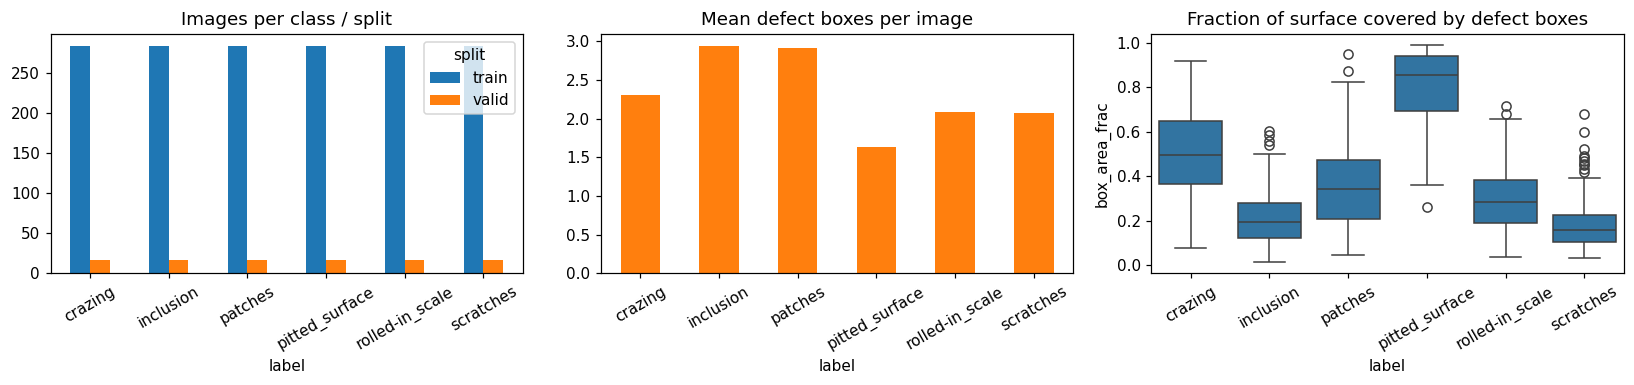

In [ ]:
# ---- image & annotation statistics
sample = df.sample(min(200, len(df)), random_state=SEED)
shapes, means, stds = [], [], []
for p in sample.path:
    im = cv2.imread(p, cv2.IMREAD_UNCHANGED)
    shapes.append(im.shape); g = im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    means.append(g.mean()); stds.append(g.std())
print("Image shapes (sample):", pd.Series([str(s) for s in shapes]).value_counts().to_dict())
print("Dtype:", im.dtype, "| channels:", 1 if im.ndim == 2 else im.shape[2])
print(f"Intensity mean {np.mean(means):.1f} ± {np.std(means):.1f} | contrast (std) {np.mean(stds):.1f} ± {np.std(stds):.1f}")

H0, W0 = shapes[0][:2]
def box_frac(r):
    if not r.boxes: return 0.0
    m = np.zeros((H0, W0), bool)
    for x1, y1, x2, y2 in r.boxes: m[max(0,y1):y2, max(0,x1):x2] = True
    return m.mean()
df["box_area_frac"] = df.apply(box_frac, axis=1)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
pd.crosstab(df.label, df.split).plot.bar(ax=ax[0], rot=30, title="Images per class / split")
df.groupby("label").n_boxes.mean().plot.bar(ax=ax[1], rot=30, color="tab:orange", title="Mean defect boxes per image")
sns.boxplot(data=df, x="label", y="box_area_frac", ax=ax[2]); ax[2].tick_params(axis="x", rotation=30)
ax[2].set_title("Fraction of surface covered by defect boxes")
plt.tight_layout(); save_fig("01_dataset_stats"); plt.show()

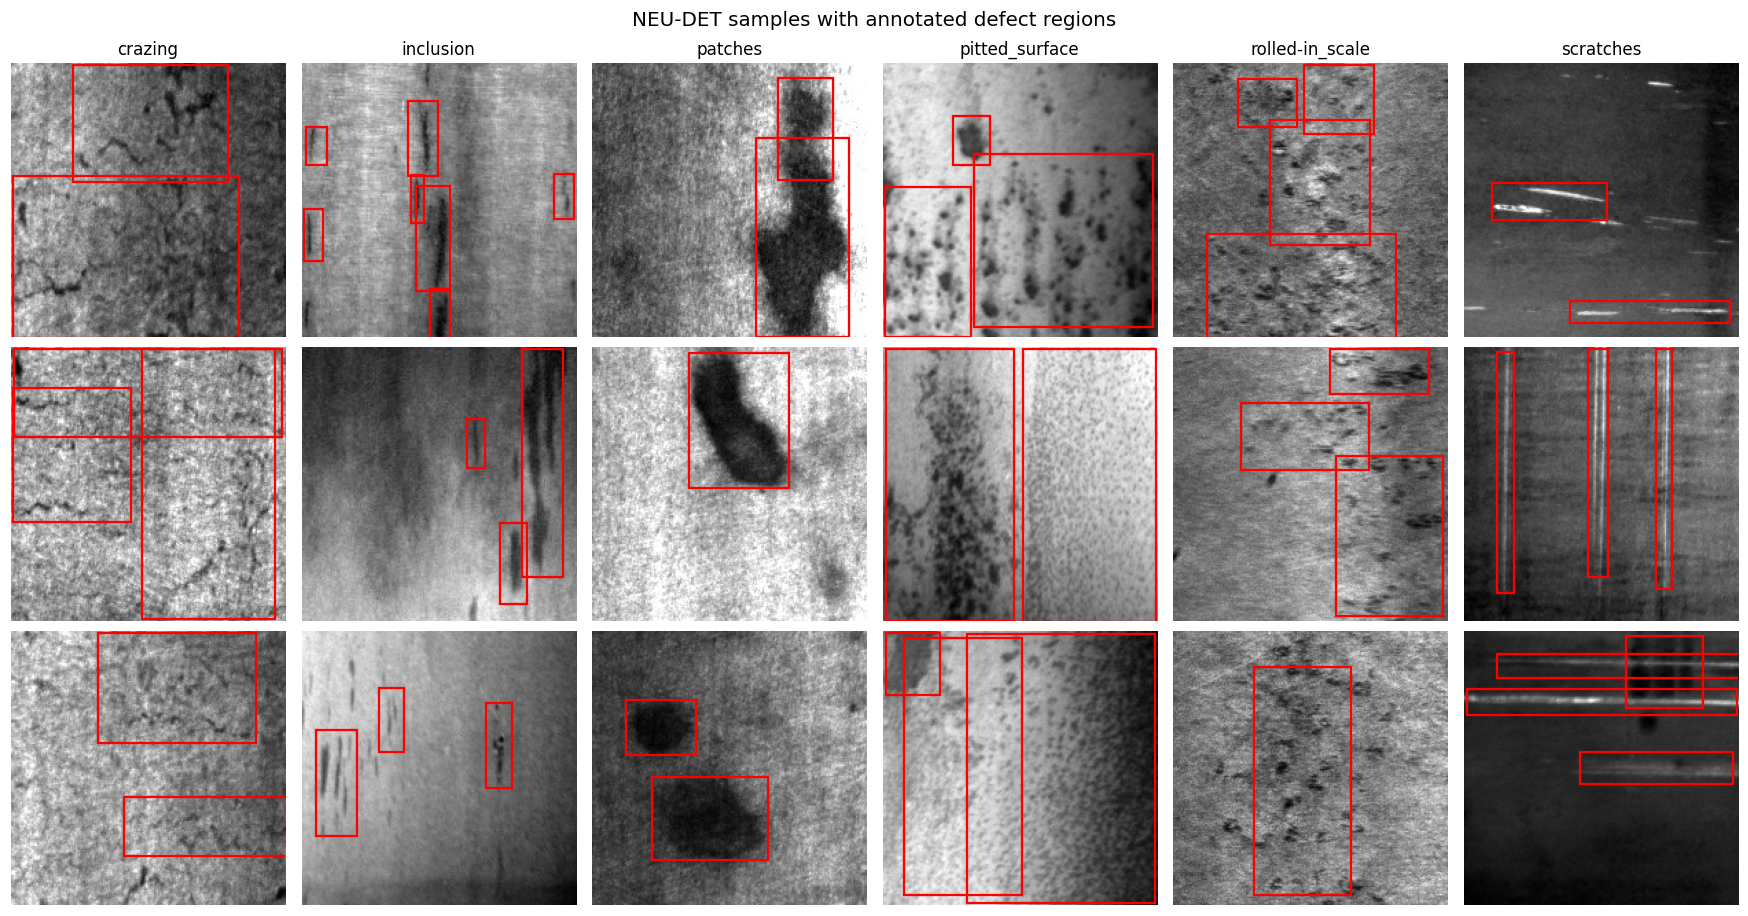

In [ ]:
# ---- representative images with ground-truth boxes
fig, axes = plt.subplots(3, 6, figsize=(16, 8.5))
for j, c in enumerate(CLASSES):
    rows = df[df.label == c].sample(3, random_state=SEED)
    for i, r in enumerate(rows.itertuples()):
        a = axes[i, j]; a.imshow(cv2.imread(r.path, 0), cmap="gray")
        for x1, y1, x2, y2 in r.boxes:
            a.add_patch(mpatches.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec="red", lw=1.5))
        a.axis("off")
        if i == 0: a.set_title(c, fontsize=11)
plt.suptitle("NEU-DET samples with annotated defect regions", fontsize=13)
plt.tight_layout(); save_fig("02_samples"); plt.show()

## 4. Preprocessing (Tasks 2 & 3)
* **Grayscale conversion** – steel surfaces carry no colour information; HOG works on intensity gradients.
* **Common resolution** – full images → `128×128` (INTER_AREA to avoid aliasing); patches are cut at native
  resolution (`64×64`) so defect scale is preserved.
* **No histogram equalisation** – HOG's block-wise L2-Hys normalisation already gives local illumination invariance;
  leaving brightness untouched also keeps the robustness experiment honest.

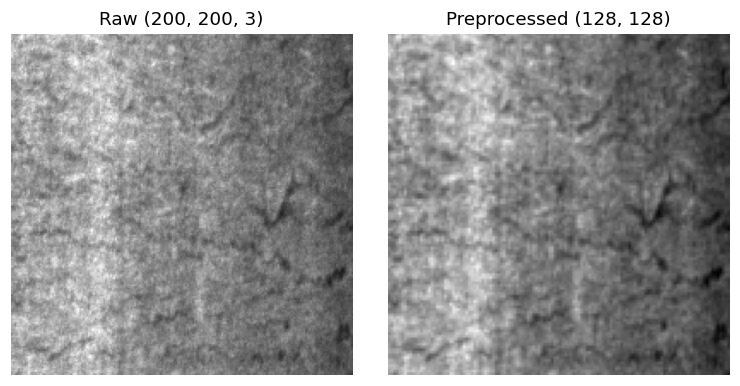

In [ ]:
def to_gray(img):
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2GRAY if img.shape[2] == 4 else cv2.COLOR_BGR2GRAY)
    if img.dtype != np.uint8:
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return img

def load_gray(path):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None: raise IOError(f"Cannot read {path}")
    return to_gray(img)

def preprocess(img, size=None):
    g = to_gray(img)
    if size is not None and g.shape[:2] != (size, size):
        interp = cv2.INTER_AREA if min(g.shape[:2]) > size else cv2.INTER_LINEAR
        g = cv2.resize(g, (size, size), interpolation=interp)
    return g

r = df.iloc[0]
raw = cv2.imread(r.path, cv2.IMREAD_COLOR)
pre = preprocess(raw, IMG_SIZE)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Raw {raw.shape}")
ax[1].imshow(pre, cmap="gray"); ax[1].set_title(f"Preprocessed {pre.shape}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 5. Building the binary (Defective / Non-Defective) dataset
* Defective patch: 64×64 window centred on a box (kept only if ≥50 % of the box, or of the window, is defect).
* Non-defective patch: random 64×64 window with **zero overlap** with any box expanded by a 4-px safety margin.
* Patches inherit the train/valid split of their parent image, and the parent image ID is kept as a **group** so
  cross-validation never puts patches of the same image in both train and test folds (no leakage).

,train,valid
1 DEFECTIVE,3221,186
0 NON-DEFECTIVE,2014,106


Clean patches by source class (train):


col_0,0,1
row_0,,
crazing,236,633
inclusion,460,616
patches,341,688
pitted_surface,54,439
rolled-in_scale,437,574
scratches,486,271


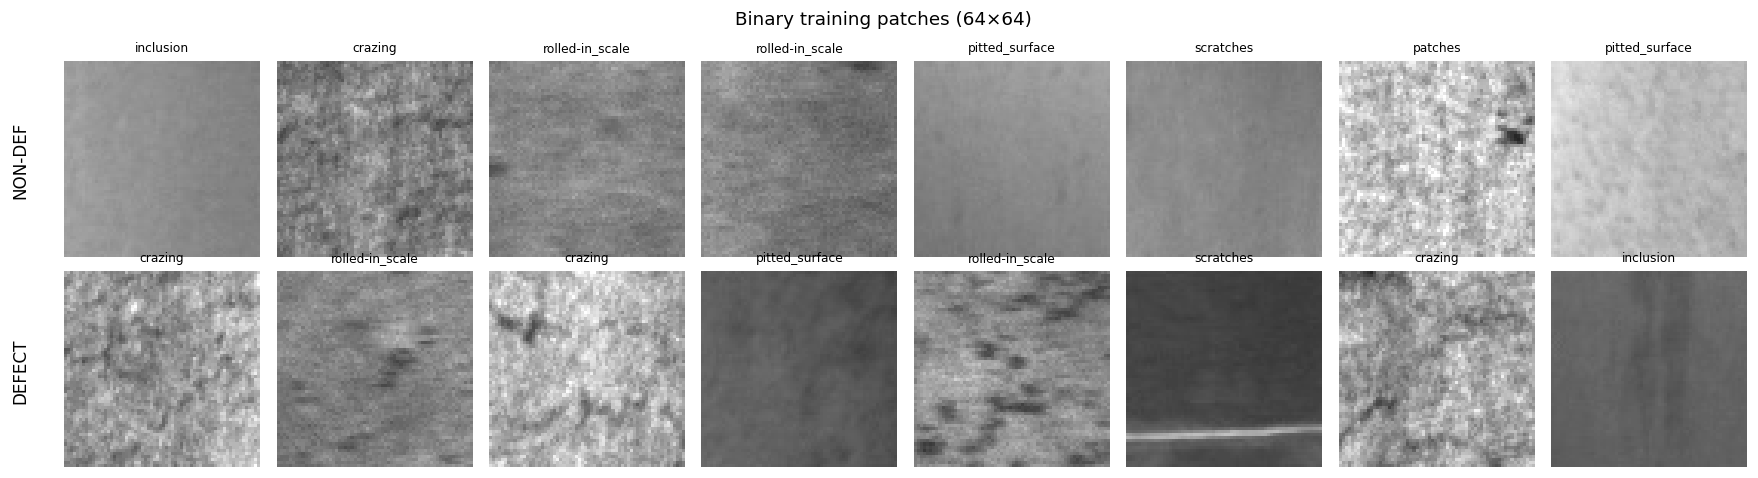

In [ ]:
MAX_DEFECT_PER_IMG, N_NORMAL_PER_IMG, MARGIN = 3, 2, 4

def inter_area(a, b):
    w = min(a[2], b[2]) - max(a[0], b[0]); h = min(a[3], b[3]) - max(a[1], b[1])
    return max(0, w) * max(0, h)

def extract_patches(dsplit, rng):
    X, y, src, grp = [], [], [], []
    for r in dsplit.itertuples():
        if not r.boxes: continue
        img = load_gray(r.path); H, W = img.shape
        if H < PATCH or W < PATCH: continue
        boxes = [(max(0,x1), max(0,y1), min(W,x2), min(H,y2)) for x1, y1, x2, y2 in r.boxes]
        # defective patches
        order = rng.permutation(len(boxes))[:MAX_DEFECT_PER_IMG]
        for k in order:
            x1, y1, x2, y2 = boxes[k]
            x0 = int(np.clip((x1 + x2) // 2 - PATCH // 2, 0, W - PATCH))
            y0 = int(np.clip((y1 + y2) // 2 - PATCH // 2, 0, H - PATCH))
            win = (x0, y0, x0 + PATCH, y0 + PATCH)
            if inter_area(win, boxes[k]) >= 0.5 * min((x2-x1)*(y2-y1), PATCH*PATCH):
                X.append(img[y0:y0+PATCH, x0:x0+PATCH]); y.append(1); src.append(r.label); grp.append(r.stem)
        # non-defective patches
        exp = [(x1-MARGIN, y1-MARGIN, x2+MARGIN, y2+MARGIN) for x1, y1, x2, y2 in boxes]
        got = 0
        for _ in range(80):
            if got >= N_NORMAL_PER_IMG: break
            x0, y0 = rng.integers(0, W - PATCH + 1), rng.integers(0, H - PATCH + 1)
            win = (x0, y0, x0 + PATCH, y0 + PATCH)
            if all(inter_area(win, b) == 0 for b in exp):
                X.append(img[y0:y0+PATCH, x0:x0+PATCH]); y.append(0); src.append(r.label); grp.append(r.stem)
                got += 1
    return np.array(X, np.uint8), np.array(y), np.array(src), np.array(grp)

rng = np.random.default_rng(SEED)
Pb_tr, yb_tr, srcb_tr, gb_tr = extract_patches(df[df.split == "train"], rng)
Pb_va, yb_va, srcb_va, gb_va = extract_patches(df[df.split == "valid"], rng)
assert (yb_tr == 0).sum() > 20, "Too few clean patches – check that XML annotations were found."

summary = pd.DataFrame({"train": pd.Series(yb_tr).value_counts(), "valid": pd.Series(yb_va).value_counts()})
summary.index = summary.index.map({0: "0 NON-DEFECTIVE", 1: "1 DEFECTIVE"})
display(summary)
print("Clean patches by source class (train):"); display(pd.crosstab(srcb_tr, yb_tr))

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for row, lab in enumerate([0, 1]):
    idx = rng.choice(np.where(yb_tr == lab)[0], 8, replace=False)
    for a, i in zip(axes[row], idx):
        a.imshow(Pb_tr[i], cmap="gray", vmin=0, vmax=255); a.axis("off"); a.set_title(srcb_tr[i], fontsize=8)
    axes[row, 0].text(-12, PATCH/2, ["NON-DEF", "DEFECT"][lab], rotation=90, va="center", ha="right", fontsize=11)
plt.suptitle("Binary training patches (64×64)"); plt.tight_layout(); save_fig("03_binary_patches"); plt.show()

## 6. HOG feature extraction & visualisation (Tasks 4 & 5)
HOG: gradients → per-cell orientation histograms (unsigned, 0–180°) → overlapping 2×2-cell blocks, L2-Hys normalised →
concatenated feature vector. Dimension = `blocks_y × blocks_x × 2 × 2 × orientations`.

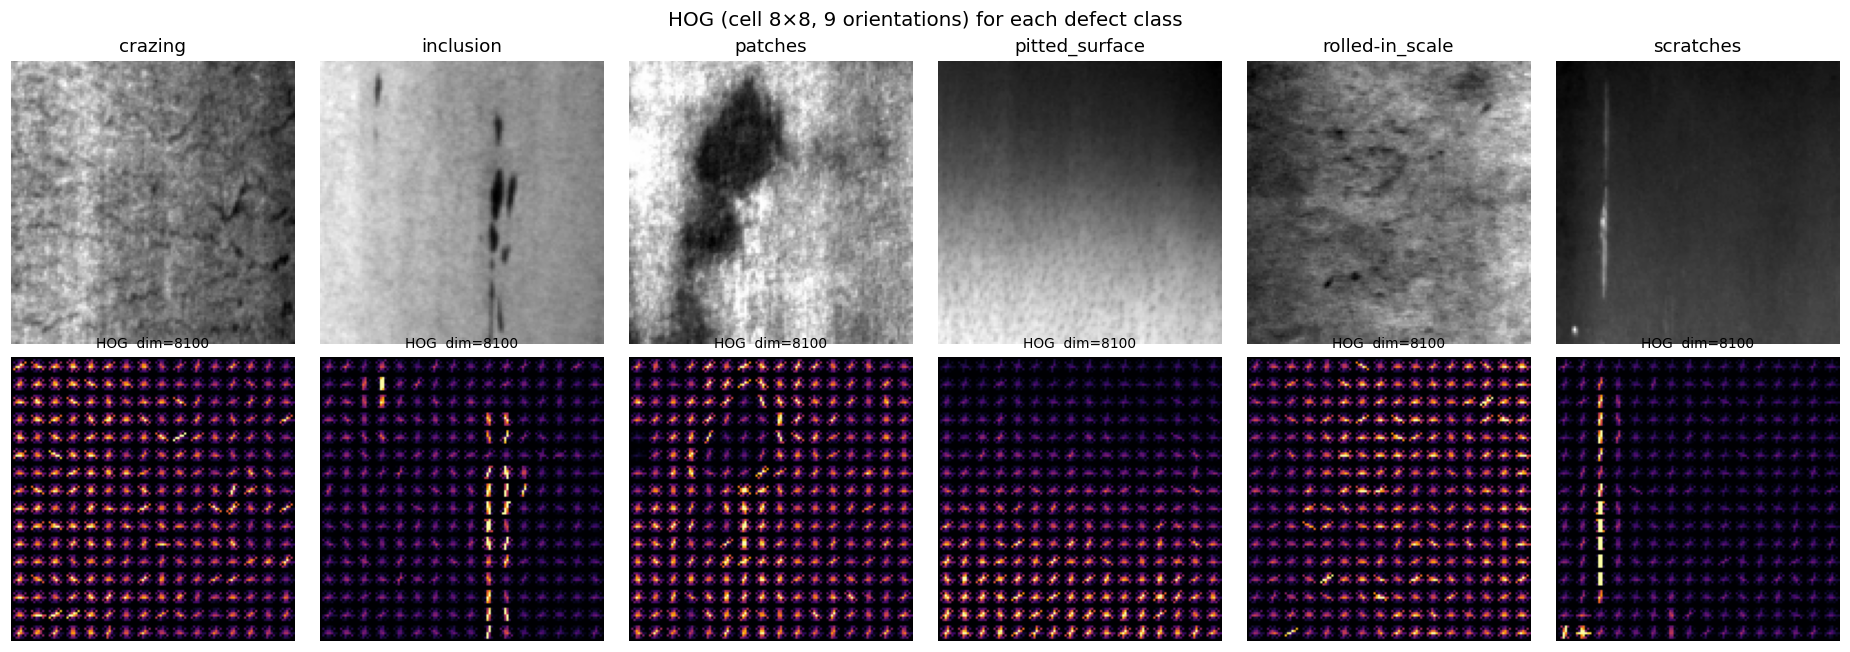

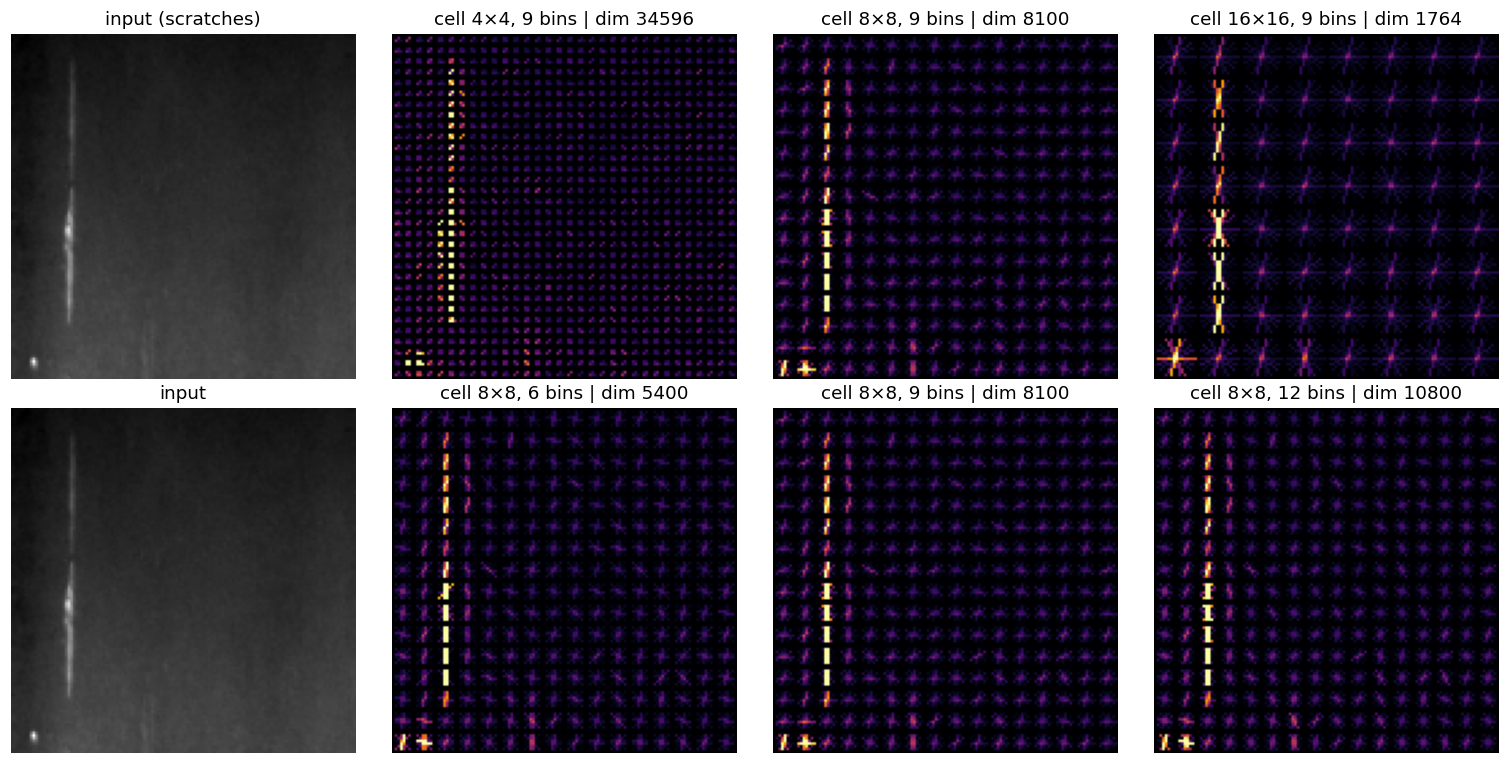

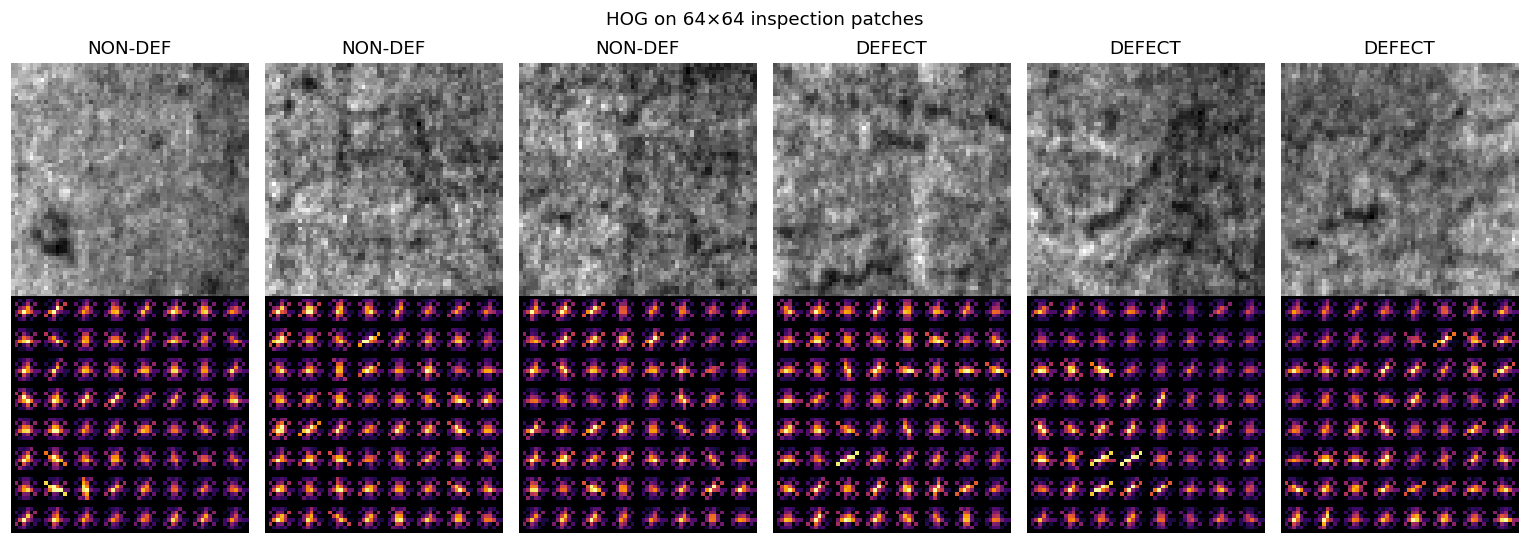

In [ ]:
def hog_one(img, ppc=8, orient=9, cpb=CELLS_PER_BLOCK, visualize=False):
    return hog(img, orientations=orient, pixels_per_cell=(ppc, ppc), cells_per_block=(cpb, cpb),
               block_norm="L2-Hys", feature_vector=True, visualize=visualize)

def hog_batch(imgs, ppc=8, orient=9):
    return np.stack([hog_one(im, ppc, orient) for im in imgs]).astype(np.float32)

def hog_vis(img, ppc, orient):
    f, h = hog_one(img, ppc, orient, visualize=True)
    return f, exposure.rescale_intensity(h, in_range=(0, np.percentile(h, 99.5) + 1e-9))

# (a) one image per class
fig, axes = plt.subplots(2, 6, figsize=(17, 6))
for j, c in enumerate(CLASSES):
    im = preprocess(load_gray(df[df.label == c].iloc[0].path), IMG_SIZE)
    f, h = hog_vis(im, 8, 9)
    axes[0, j].imshow(im, cmap="gray"); axes[0, j].set_title(c)
    axes[1, j].imshow(h, cmap="inferno"); axes[1, j].set_title(f"HOG  dim={f.size}", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.suptitle("HOG (cell 8×8, 9 orientations) for each defect class", fontsize=13)
plt.tight_layout(); save_fig("04_hog_per_class"); plt.show()

# (b) effect of cell size / orientations on the same image
im = preprocess(load_gray(df[df.label == "scratches"].iloc[0].path), IMG_SIZE)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(im, cmap="gray"); axes[0, 0].set_title("input (scratches)")
axes[1, 0].imshow(im, cmap="gray"); axes[1, 0].set_title("input")
for k, ppc in enumerate(CELL_SIZES):
    f, h = hog_vis(im, ppc, 9);  axes[0, k+1].imshow(h, cmap="inferno"); axes[0, k+1].set_title(f"cell {ppc}×{ppc}, 9 bins | dim {f.size}")
for k, ori in enumerate(ORIENTATIONS):
    f, h = hog_vis(im, 8, ori);  axes[1, k+1].imshow(h, cmap="inferno"); axes[1, k+1].set_title(f"cell 8×8, {ori} bins | dim {f.size}")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); save_fig("05_hog_params_visual"); plt.show()

# (c) clean vs defective patches
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for j, i in enumerate(list(np.where(yb_tr == 0)[0][:3]) + list(np.where(yb_tr == 1)[0][:3])):
    f, h = hog_vis(Pb_tr[i], 8, 9)
    axes[0, j].imshow(Pb_tr[i], cmap="gray"); axes[0, j].set_title(["NON-DEF", "DEFECT"][yb_tr[i]])
    axes[1, j].imshow(h, cmap="inferno")
for a in axes.ravel(): a.axis("off")
plt.suptitle("HOG on 64×64 inspection patches"); plt.tight_layout(); save_fig("06_hog_patches"); plt.show()

In [ ]:
# ---- assemble both tasks
tr, va = df[df.split == "train"].reset_index(drop=True), df[df.split == "valid"].reset_index(drop=True)
TASKS = {
    "binary": dict(title="Binary: Defective vs Non-Defective (64×64 patches)",
                   Xtr=Pb_tr, ytr=yb_tr, gtr=gb_tr, Xva=Pb_va, yva=yb_va,
                   classes=["NON-DEFECTIVE", "DEFECTIVE"]),
    "multiclass": dict(title="Multi-class: 6 defect types (128×128 full images)",
                       Xtr=np.stack([preprocess(load_gray(p), IMG_SIZE) for p in tr.path]), ytr=tr.y.values,
                       gtr=tr.stem.values,
                       Xva=np.stack([preprocess(load_gray(p), IMG_SIZE) for p in va.path]), yva=va.y.values,
                       classes=CLASSES),
}
for k, t in TASKS.items():
    print(f"{k:10s}  train {t['Xtr'].shape}  valid {t['Xva'].shape}")

binary      train (5235, 64, 64)  valid (292, 64, 64)
multiclass  train (1700, 128, 128)  valid (100, 128, 128)


## 7. HOG parameter study (Task 11)
All 9 combinations of cell size {4, 8, 16} × orientations {6, 9, 12} are scored by **5-fold group-stratified
cross-validation on the training set only** with a standardised linear SVM (a fast, fair probe of representation
quality). The validation split is never touched here, so the chosen configuration is not tuned on test data.

In [ ]:
def hog_grid(task):
    cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    rows = []
    for ppc in CELL_SIZES:
        for ori in ORIENTATIONS:
            t0 = time.perf_counter(); F = hog_batch(task["Xtr"], ppc, ori)
            ms = (time.perf_counter() - t0) / len(F) * 1e3
            pipe = make_pipeline(StandardScaler(), LinearSVC(C=0.01, class_weight="balanced", max_iter=20000))
            s = cross_validate(pipe, F, task["ytr"], groups=task["gtr"], cv=cv,
                               scoring=["accuracy", "f1_macro"], n_jobs=-1)
            rows.append(dict(cell=f"{ppc}x{ppc}", ppc=ppc, orientations=ori, dim=F.shape[1], hog_ms=ms,
                             cv_acc=s["test_accuracy"].mean(), cv_f1=s["test_f1_macro"].mean(),
                             cv_f1_std=s["test_f1_macro"].std()))
            print(f"  cell {ppc:>2}  orient {ori:>2}  dim {F.shape[1]:>6}  CV-F1 {rows[-1]['cv_f1']:.3f}±{rows[-1]['cv_f1_std']:.3f}")
            del F
    return pd.DataFrame(rows)

GRID, BEST_HOG = {}, {}
for k, t in TASKS.items():
    print(t["title"]); GRID[k] = hog_grid(t)
    best = GRID[k].sort_values(["cv_f1", "dim"], ascending=[False, True]).iloc[0]
    BEST_HOG[k] = dict(ppc=int(best.ppc), orient=int(best.orientations))
    print(f"  -> best: cell {BEST_HOG[k]['ppc']}×{BEST_HOG[k]['ppc']}, {BEST_HOG[k]['orient']} orientations\n")

Binary: Defective vs Non-Defective (64×64 patches)
  cell  4  orient  6  dim   5400  CV-F1 0.651±0.013
  cell  4  orient  9  dim   8100  CV-F1 0.640±0.005
  cell  4  orient 12  dim  10800  CV-F1 0.644±0.005
  cell  8  orient  6  dim   1176  CV-F1 0.726±0.007
  cell  8  orient  9  dim   1764  CV-F1 0.709±0.013
  cell  8  orient 12  dim   2352  CV-F1 0.705±0.014
  cell 16  orient  6  dim    216  CV-F1 0.714±0.004
  cell 16  orient  9  dim    324  CV-F1 0.725±0.008
  cell 16  orient 12  dim    432  CV-F1 0.722±0.010
  -> best: cell 8×8, 6 orientations

Multi-class: 6 defect types (128×128 full images)
  cell  4  orient  6  dim  23064  CV-F1 0.570±0.021
  cell  4  orient  9  dim  34596  CV-F1 0.608±0.010
  cell  4  orient 12  dim  46128  CV-F1 0.638±0.010
  cell  8  orient  6  dim   5400  CV-F1 0.564±0.006
  cell  8  orient  9  dim   8100  CV-F1 0.597±0.003
  cell  8  orient 12  dim  10800  CV-F1 0.623±0.010
  cell 16  orient  6  dim   1176  CV-F1 0.726±0.011
  cell 16  orient  9  dim   17

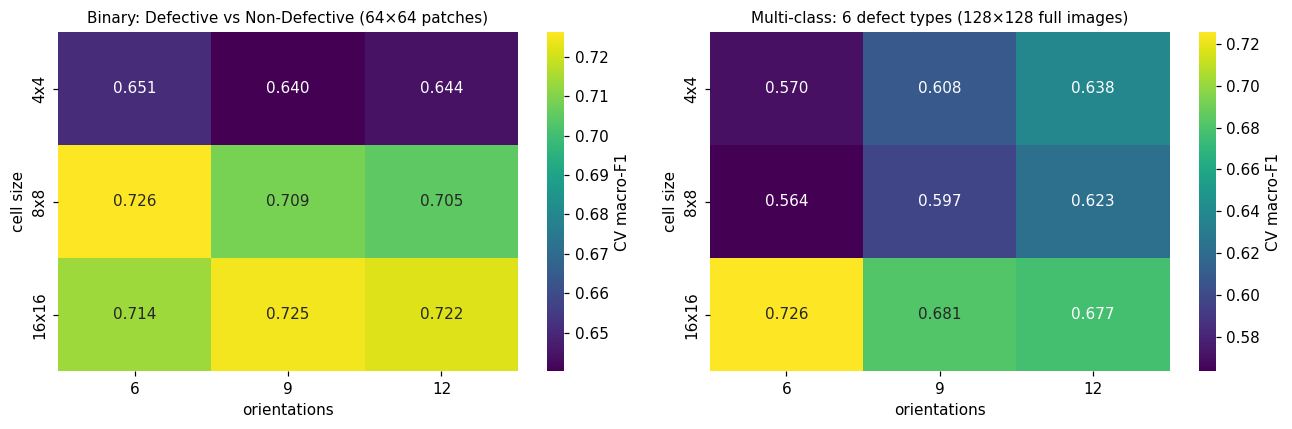

Binary: Defective vs Non-Defective (64×64 patches)


,cell,orientations,dim,hog_ms,cv_acc,cv_f1,cv_f1_std
0,4x4,6,5400,5.87,0.6648,0.6508,0.0133
1,4x4,9,8100,6.03,0.6527,0.6402,0.0047
2,4x4,12,10800,5.74,0.6545,0.6440,0.0049
3,8x8,6,1176,1.65,0.7345,0.7263,0.0068
4,8x8,9,1764,1.68,0.7184,0.7088,0.0126
5,8x8,12,2352,1.57,0.7152,0.7048,0.0135
6,16x16,6,216,0.60,0.7198,0.7136,0.0038
7,16x16,9,324,0.83,0.7318,0.7249,0.0078
8,16x16,12,432,0.75,0.7293,0.7217,0.0099


Multi-class: 6 defect types (128×128 full images)


,cell,orientations,dim,hog_ms,cv_acc,cv_f1,cv_f1_std
0,4x4,6,23064,22.60,0.5783,0.5703,0.0207
1,4x4,9,34596,23.27,0.6188,0.6081,0.0102
2,4x4,12,46128,23.72,0.6506,0.6385,0.0098
3,8x8,6,5400,6.68,0.5700,0.5637,0.0063
4,8x8,9,8100,6.81,0.6053,0.5969,0.0032
5,8x8,12,10800,7.10,0.6341,0.6230,0.0096
6,16x16,6,1176,2.40,0.7270,0.7255,0.0113
7,16x16,9,1764,2.72,0.6818,0.6815,0.0093
8,16x16,12,2352,2.94,0.6777,0.6770,0.0185


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for a, (k, g) in zip(axes, GRID.items()):
    piv = g.pivot(index="cell", columns="orientations", values="cv_f1").loc[[f"{c}x{c}" for c in CELL_SIZES]]
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=a, cbar_kws={"label": "CV macro-F1"})
    a.set_title(TASKS[k]["title"], fontsize=10); a.set_ylabel("cell size"); a.set_xlabel("orientations")
plt.tight_layout(); save_fig("07_hog_param_heatmap"); plt.show()

for k, g in GRID.items():
    print(TASKS[k]["title"])
    display(g.drop(columns="ppc").round({"hog_ms": 2, "cv_acc": 4, "cv_f1": 4, "cv_f1_std": 4}))
    g.to_csv(f"{OUT_DIR}/hog_param_study_{k}.csv", index=False)

## 8. Classifier training & comparison (Tasks 6, 7, 8)
Using the best HOG configuration per task:

| Model | Notes |
|---|---|
| **HOG + SVM (RBF)** | main model; `C` chosen by group-CV on train; Platt-scaled probabilities for confidence |
| HOG + Random Forest | 300 trees, robust non-linear baseline |
| HOG + Logistic Regression | linear, calibrated probabilities |
| HOG + k-NN | instance-based baseline (k = 5, distance-weighted) |

In [ ]:
def fit_svm(F, y, groups):
    cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
    gs = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma="scale", class_weight="balanced")),
                      {"svc__C": [1, 10, 30]}, cv=cv, scoring="f1_macro", n_jobs=-1)
    gs.fit(F, y, groups=groups)
    C = gs.best_params_["svc__C"]
    model = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma="scale", C=C, class_weight="balanced",
                                                probability=True, random_state=SEED)).fit(F, y)
    return model, {"C": C}

def model_zoo():
    return {
        "SVM (RBF)": None,  # built by fit_svm
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEED),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=5000,
                                                                                 class_weight="balanced")),
        "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5, weights="distance", n_jobs=-1)),
    }

def metrics(y, pred, proba, binary):
    avg = "binary" if binary else "macro"
    out = dict(accuracy=accuracy_score(y, pred),
               precision=precision_score(y, pred, average=avg, zero_division=0),
               recall=recall_score(y, pred, average=avg, zero_division=0),
               f1=f1_score(y, pred, average=avg, zero_division=0),
               f1_macro=f1_score(y, pred, average="macro", zero_division=0))
    if binary: out["roc_auc"] = roc_auc_score(y, proba[:, 1])
    return out

MODELS, FEATS, RESULTS, PREDS = {}, {}, {}, {}
for k, t in TASKS.items():
    hp, binary = BEST_HOG[k], k == "binary"
    t0 = time.perf_counter(); Ftr = hog_batch(t["Xtr"], **hp)
    t1 = time.perf_counter(); Fva = hog_batch(t["Xva"], **hp)
    hog_ms = (time.perf_counter() - t1) / len(Fva) * 1e3
    FEATS[k] = (Ftr, Fva); MODELS[k], PREDS[k], rows = {}, {}, []
    print(f"\n{t['title']}  | HOG cell {hp['ppc']} / {hp['orient']} bins, dim {Ftr.shape[1]}")
    for name, m in model_zoo().items():
        t0 = time.perf_counter()
        if name == "SVM (RBF)":
            m, info = fit_svm(Ftr, t["ytr"], t["gtr"]); print(f"  SVM best C = {info['C']}")
        else:
            m.fit(Ftr, t["ytr"])
        train_s = time.perf_counter() - t0
        t0 = time.perf_counter(); proba = m.predict_proba(Fva); pred = proba.argmax(1)
        clf_ms = (time.perf_counter() - t0) / len(Fva) * 1e3
        MODELS[k][name] = m; PREDS[k][name] = (pred, proba)
        rows.append(dict(model=name, **metrics(t["yva"], pred, proba, binary),
                         train_s=train_s, infer_ms_per_img=hog_ms + clf_ms))
        print(f"  {name:20s} acc {rows[-1]['accuracy']:.4f}  F1 {rows[-1]['f1']:.4f}  ({train_s:.1f}s)")
    RESULTS[k] = pd.DataFrame(rows).set_index("model")


Binary: Defective vs Non-Defective (64×64 patches)  | HOG cell 8 / 6 bins, dim 1176
  SVM best C = 10
  SVM (RBF)            acc 0.8048  F1 0.8512  (211.8s)
  Random Forest        acc 0.7945  F1 0.8485  (62.5s)
  Logistic Regression  acc 0.7603  F1 0.7917  (1.1s)
  k-NN (k=5)           acc 0.5000  F1 0.3917  (0.1s)

Multi-class: 6 defect types (128×128 full images)  | HOG cell 16 / 6 bins, dim 1176
  SVM best C = 10
  SVM (RBF)            acc 0.9100  F1 0.9094  (13.9s)
  Random Forest        acc 0.8800  F1 0.8808  (14.1s)
  Logistic Regression  acc 0.8500  F1 0.8488  (3.4s)
  k-NN (k=5)           acc 0.7400  F1 0.6868  (0.0s)


Binary: Defective vs Non-Defective (64×64 patches) — held-out validation set (precision/recall/F1 for the DEFECTIVE class)


,accuracy,precision,recall,f1,f1_macro,roc_auc,train_s,infer_ms_per_img
model,,,,,,,,
SVM (RBF),0.8048,0.8274,0.8763,0.8512,0.7838,0.8655,211.8307,5.3227
Random Forest,0.7945,0.8000,0.9032,0.8485,0.7647,0.8719,62.5130,1.6777
Logistic Regression,0.7603,0.8867,0.7151,0.7917,0.7547,0.8464,1.0570,1.3891
k-NN (k=5),0.5000,0.8704,0.2527,0.3917,0.4836,0.7071,0.1193,1.8264


Multi-class: 6 defect types (128×128 full images) — held-out validation set (macro-averaged)


,accuracy,precision,recall,f1,f1_macro,train_s,infer_ms_per_img
model,,,,,,,
SVM (RBF),0.91,0.9107,0.9105,0.9094,0.9094,13.8845,3.6852
Random Forest,0.88,0.8917,0.8787,0.8808,0.8808,14.0910,3.3974
Logistic Regression,0.85,0.8544,0.8499,0.8488,0.8488,3.4471,2.5571
k-NN (k=5),0.74,0.8199,0.7322,0.6868,0.6868,0.0298,2.9711


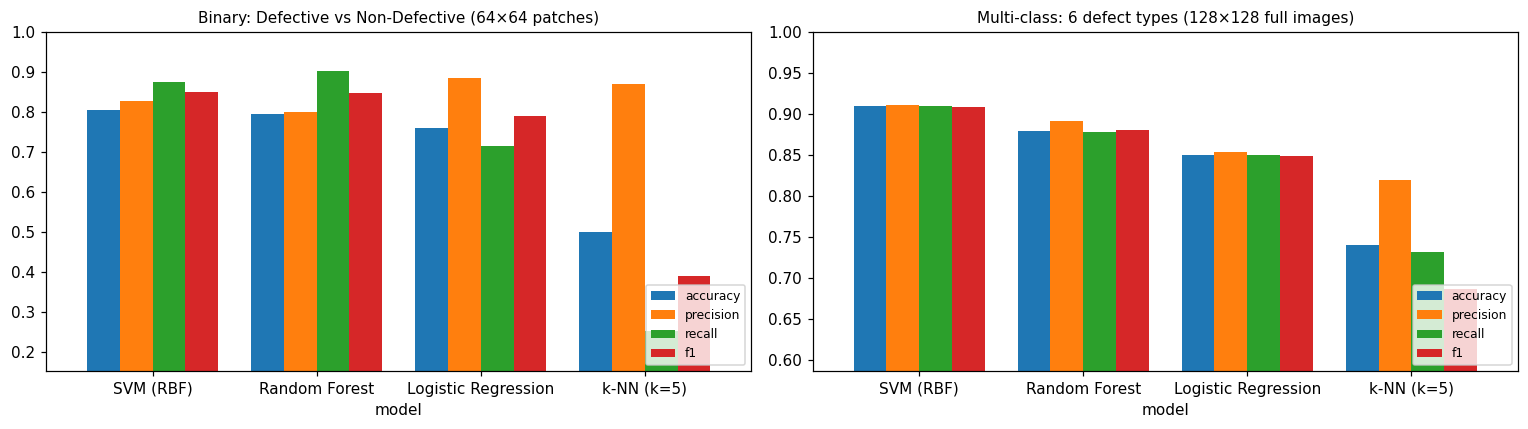

In [ ]:
for k, res in RESULTS.items():
    print(TASKS[k]["title"], "— held-out validation set",
          "(precision/recall/F1 for the DEFECTIVE class)" if k == "binary" else "(macro-averaged)")
    display(res.round(4)); res.to_csv(f"{OUT_DIR}/classifier_comparison_{k}.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for a, (k, res) in zip(axes, RESULTS.items()):
    res[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=a, rot=0, width=0.8)
    a.set_ylim(max(0, res[["accuracy","precision","recall","f1"]].values.min() - 0.1), 1.0)
    a.set_title(TASKS[k]["title"], fontsize=10); a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); save_fig("08_classifier_comparison"); plt.show()

## 9. Confusion matrices, classification reports & industrial operating point (Tasks 9 & 10)

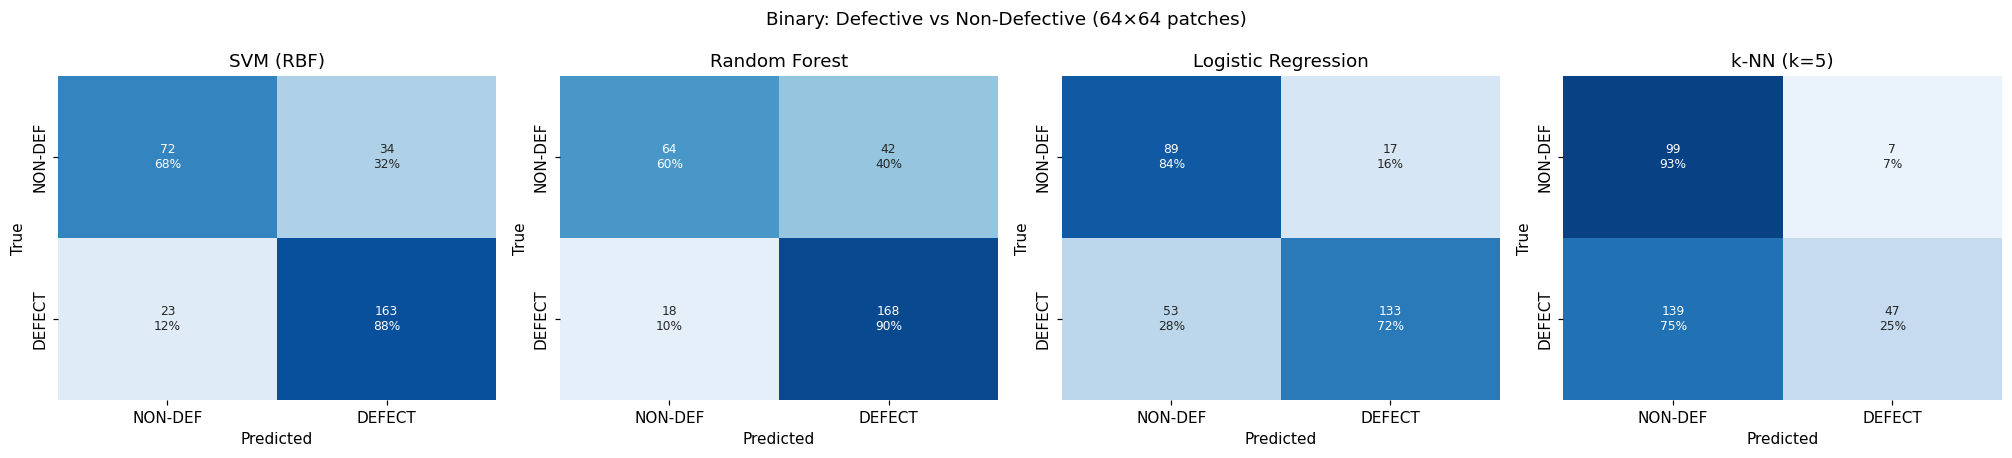

===== Binary: Defective vs Non-Defective (64×64 patches) | HOG + SVM (RBF) =====
               precision    recall  f1-score   support

NON-DEFECTIVE     0.7579    0.6792    0.7164       106
    DEFECTIVE     0.8274    0.8763    0.8512       186

     accuracy                         0.8048       292
    macro avg     0.7927    0.7778    0.7838       292
 weighted avg     0.8022    0.8048    0.8023       292

===== Binary: Defective vs Non-Defective (64×64 patches) | HOG + Random Forest =====
               precision    recall  f1-score   support

NON-DEFECTIVE     0.7805    0.6038    0.6809       106
    DEFECTIVE     0.8000    0.9032    0.8485       186

     accuracy                         0.7945       292
    macro avg     0.7902    0.7535    0.7647       292
 weighted avg     0.7929    0.7945    0.7876       292

===== Binary: Defective vs Non-Defective (64×64 patches) | HOG + Logistic Regression =====
               precision    recall  f1-score   support

NON-DEFECTIVE     0.6

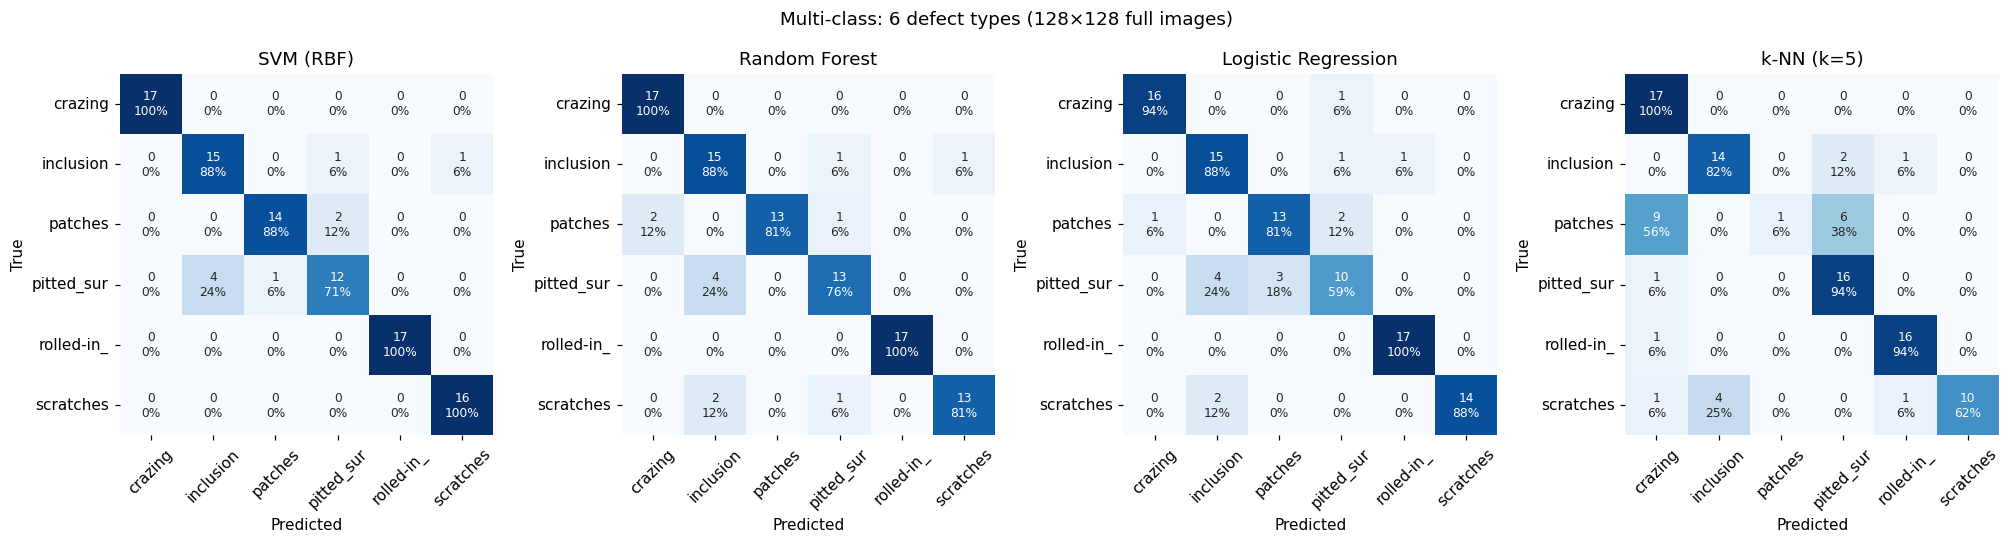

===== Multi-class: 6 defect types (128×128 full images) | HOG + SVM (RBF) =====
                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        17
      inclusion     0.7895    0.8824    0.8333        17
        patches     0.9333    0.8750    0.9032        16
 pitted_surface     0.8000    0.7059    0.7500        17
rolled-in_scale     1.0000    1.0000    1.0000        17
      scratches     0.9412    1.0000    0.9697        16

       accuracy                         0.9100       100
      macro avg     0.9107    0.9105    0.9094       100
   weighted avg     0.9101    0.9100    0.9088       100

===== Multi-class: 6 defect types (128×128 full images) | HOG + Random Forest =====
                 precision    recall  f1-score   support

        crazing     0.8947    1.0000    0.9444        17
      inclusion     0.7143    0.8824    0.7895        17
        patches     1.0000    0.8125    0.8966        16
 pitted_surface     0.8125    0.76

In [ ]:
for k, t in TASKS.items():
    names = list(MODELS[k])
    fig, axes = plt.subplots(1, len(names), figsize=(4.6 * len(names), 4.2 if k == "binary" else 5))
    for a, name in zip(axes, names):
        pred = PREDS[k][name][0]
        cm = confusion_matrix(t["yva"], pred, labels=range(len(t["classes"])))
        cmn = cm / cm.sum(1, keepdims=True)
        annot = np.array([[f"{c}\n{p:.0%}" for c, p in zip(rc, rp)] for rc, rp in zip(cm, cmn)])
        lbl = ["NON-DEF", "DEFECT"] if k == "binary" else [c[:10] for c in t["classes"]]
        sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=lbl, yticklabels=lbl, ax=a, annot_kws={"fontsize": 8})
        a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("True")
        a.tick_params(axis="x", rotation=45 if k != "binary" else 0)
    plt.suptitle(t["title"]); plt.tight_layout(); save_fig(f"09_confusion_{k}"); plt.show()
    for name in names:
        print(f"===== {t['title']} | HOG + {name} =====")
        print(classification_report(t["yva"], PREDS[k][name][0], target_names=t["classes"], digits=4))

Decision threshold for >= 95% defect recall (train OOF): 0.343


,accuracy,defect_recall,defect_precision,f1,missed_defects,false_rejects
threshold,,,,,,
default 0.50,0.8014,0.8817,0.8200,0.8497,22,36
recall-targeted 0.34,0.7671,0.9462,0.7521,0.8381,10,58


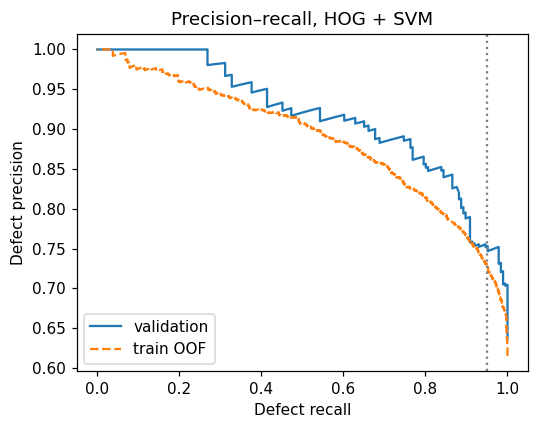

Binary accuracy split by the parent image's defect type:


true,acc on clean patches,acc on defect patches
source_class,,
crazing,0.067,0.917
inclusion,0.792,0.968
patches,0.118,1.000
pitted_surface,NaN,0.966
rolled-in_scale,0.350,0.872
scratches,0.633,1.000


In [ ]:
# ---- operating point for the binary inspector (chosen on TRAIN out-of-fold predictions, never on valid)
t, svm = TASKS["binary"], MODELS["binary"]["SVM (RBF)"]
Ftr, Fva = FEATS["binary"]
oof = cross_val_predict(svm, Ftr, t["ytr"], groups=t["gtr"], method="predict_proba", n_jobs=-1,
                        cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED))[:, 1]
prec, rec, thr = precision_recall_curve(t["ytr"], oof)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
THRESHOLD = float(thr[ok[np.argmax(prec[:-1][ok])]]) if len(ok) else 0.5
print(f"Decision threshold for >= {TARGET_RECALL:.0%} defect recall (train OOF): {THRESHOLD:.3f}")

p_va = PREDS["binary"]["SVM (RBF)"][1][:, 1]
rows = []
for name, th in [("default 0.50", 0.5), (f"recall-targeted {THRESHOLD:.2f}", THRESHOLD)]:
    pr = (p_va >= th).astype(int); tn, fp, fn, tp = confusion_matrix(t["yva"], pr).ravel()
    rows.append(dict(threshold=name, accuracy=accuracy_score(t["yva"], pr),
                     defect_recall=tp/(tp+fn), defect_precision=tp/max(1, tp+fp), f1=f1_score(t["yva"], pr),
                     missed_defects=fn, false_rejects=fp))
display(pd.DataFrame(rows).set_index("threshold").round(4))

pv, rv, _ = precision_recall_curve(t["yva"], p_va)
plt.figure(figsize=(5, 4)); plt.plot(rv, pv, label="validation"); plt.plot(rec, prec, "--", label="train OOF")
plt.axvline(TARGET_RECALL, color="gray", ls=":"); plt.xlabel("Defect recall"); plt.ylabel("Defect precision")
plt.title("Precision–recall, HOG + SVM"); plt.legend(); plt.tight_layout(); save_fig("10_pr_curve"); plt.show()

# ---- error analysis: does the patch classifier depend on the steel's background texture?
err = pd.DataFrame({"source_class": srcb_va, "true": t["yva"], "pred": (p_va >= THRESHOLD).astype(int)})
err["correct"] = err.true == err.pred
print("Binary accuracy split by the parent image's defect type:")
display(err.pivot_table(index="source_class", columns="true", values="correct", aggfunc="mean")
           .rename(columns={0: "acc on clean patches", 1: "acc on defect patches"}).round(3))

## 10. Robustness analysis (Task 12)
Trained models are re-evaluated on the validation set after realistic imaging degradations, applied **after**
preprocessing and **before** HOG (as would happen with a degraded camera feed):

| Condition | Levels | Industrial cause |
|---|---|---|
| Brightness offset | −80, −40, +40, +80 | lamp ageing, exposure drift |
| Gaussian noise σ | 5, 10, 20, 30 | sensor noise, high gain |
| Rotation | 5°, 15°, 30°, 90° | part mis-alignment on the conveyor |
| Gaussian blur σ | 0.5, 1, 2, 3 | defocus, motion blur |

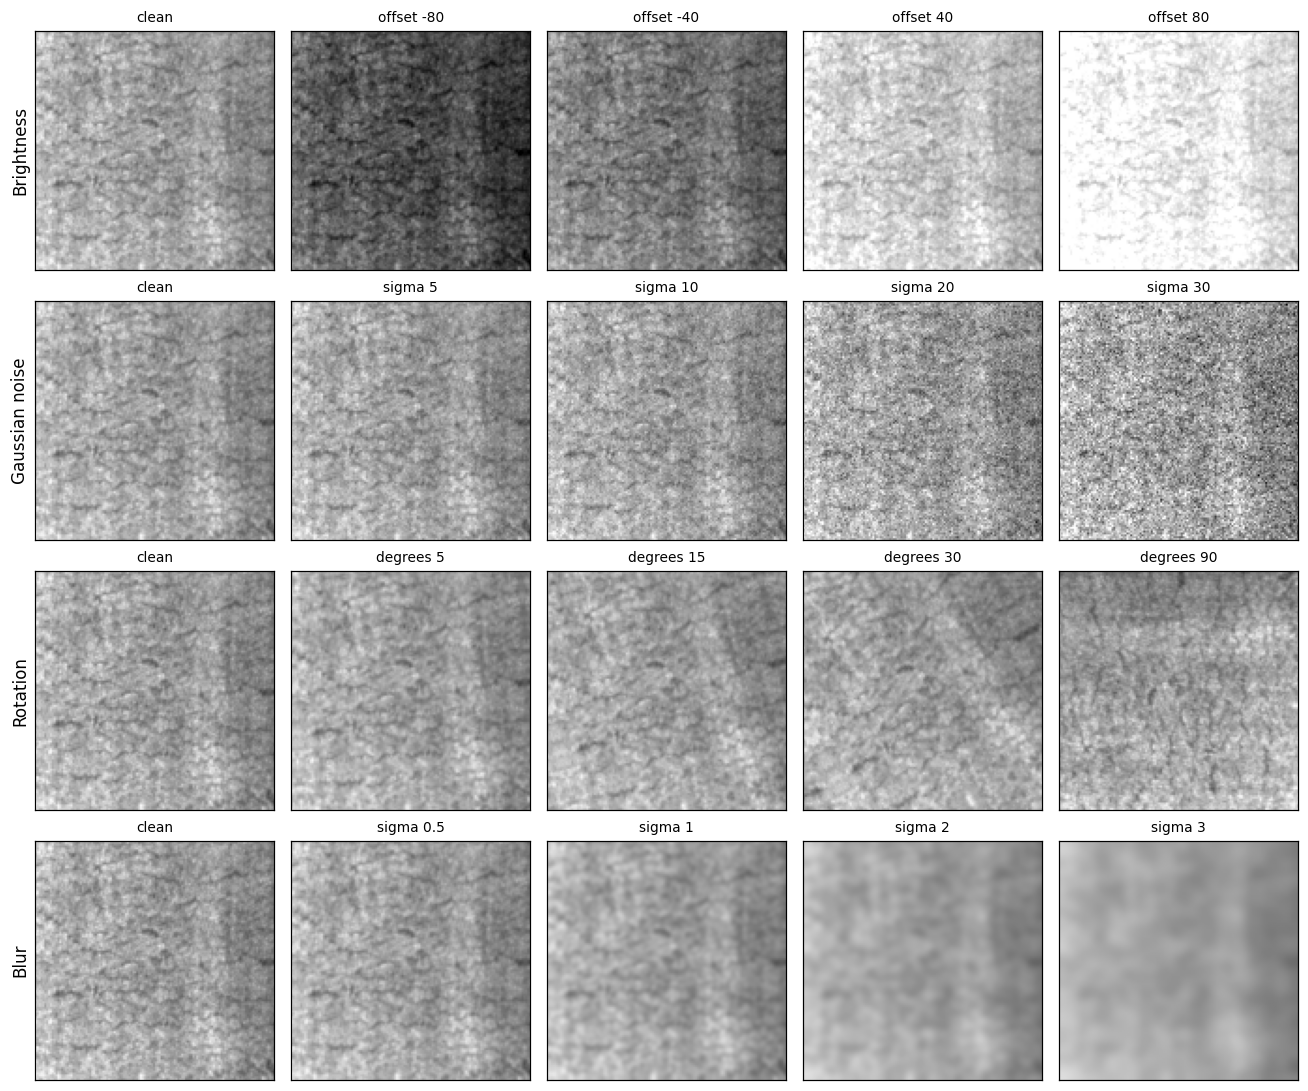

Robustness: Binary: Defective vs Non-Defective (64×64 patches)
Robustness: Multi-class: 6 defect types (128×128 full images)


In [ ]:
def brightness(im, d): return np.clip(im.astype(np.int16) + d, 0, 255).astype(np.uint8)
def noise(im, s, seed=0):
    r = np.random.default_rng(seed); return np.clip(im + r.normal(0, s, im.shape), 0, 255).astype(np.uint8)
def rotate(im, a):
    h, w = im.shape; M = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
    return cv2.warpAffine(im, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
def blur(im, s): return cv2.GaussianBlur(im, (0, 0), s)

PERTURB = {
    "Brightness": ("offset", [-80, -40, 40, 80], brightness),
    "Gaussian noise": ("sigma", [5, 10, 20, 30], lambda im, s: noise(im, s, seed=int(s))),
    "Rotation": ("degrees", [5, 15, 30, 90], rotate),
    "Blur": ("sigma", [0.5, 1, 2, 3], blur),
}

# visual check
im = TASKS["multiclass"]["Xva"][0]
fig, axes = plt.subplots(4, 5, figsize=(12, 10))
for i, (pn, (unit, levels, fn)) in enumerate(PERTURB.items()):
    axes[i, 0].imshow(im, cmap="gray", vmin=0, vmax=255); axes[i, 0].set_title("clean", fontsize=9)
    axes[i, 0].set_ylabel(pn, fontsize=11)
    for j, lv in enumerate(levels):
        axes[i, j+1].imshow(fn(im, lv), cmap="gray", vmin=0, vmax=255); axes[i, j+1].set_title(f"{unit} {lv}", fontsize=9)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); save_fig("11_perturbation_examples"); plt.show()

def robustness(k, models):
    t, hp, binary = TASKS[k], BEST_HOG[k], k == "binary"
    rows = []
    base_F = FEATS[k][1]
    for name, m in models.items():
        pr = m.predict_proba(base_F)
        rows.append(dict(condition="Clean", level=0, model=name, **metrics(t["yva"], pr.argmax(1), pr, binary)))
    for pn, (unit, levels, fn) in PERTURB.items():
        for lv in levels:
            F = hog_batch([fn(x, lv) for x in t["Xva"]], **hp)
            for name, m in models.items():
                pr = m.predict_proba(F)
                rows.append(dict(condition=pn, level=lv, model=name, **metrics(t["yva"], pr.argmax(1), pr, binary)))
    R = pd.DataFrame(rows)
    clean = R[R.condition == "Clean"].set_index("model")
    R["d_accuracy"] = R.accuracy - R.model.map(clean.accuracy)
    R["d_f1"] = R.f1 - R.model.map(clean.f1)
    return R

ROB = {}
for k in TASKS:
    print("Robustness:", TASKS[k]["title"]); ROB[k] = robustness(k, MODELS[k])
    ROB[k].to_csv(f"{OUT_DIR}/robustness_{k}.csv", index=False)

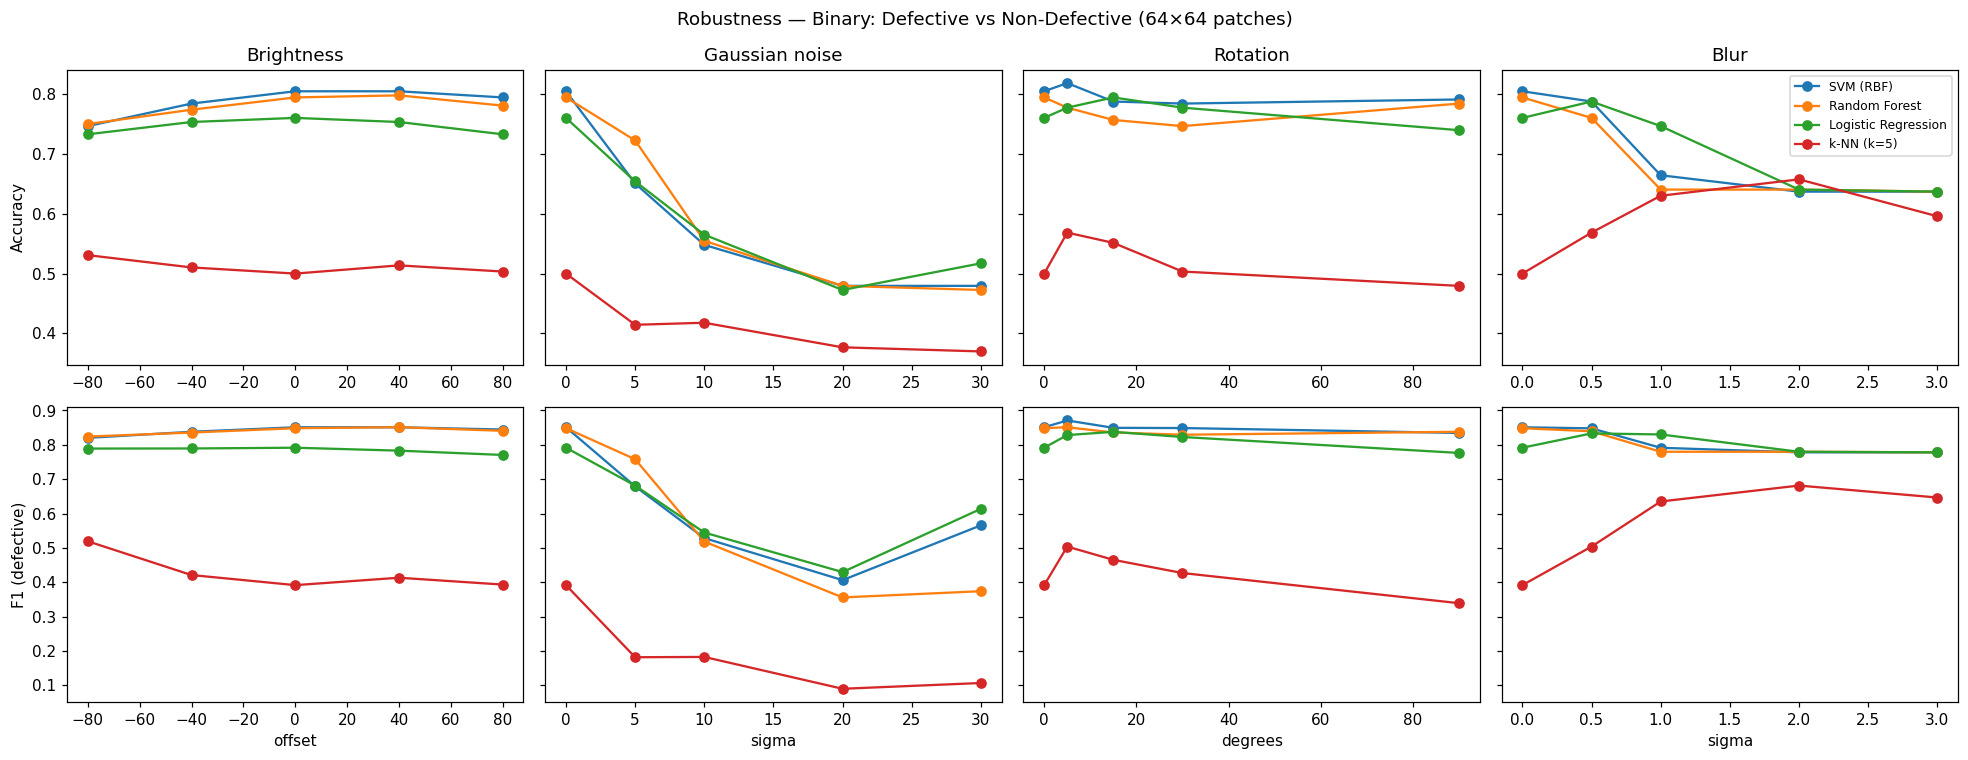

Largest drop vs clean (Δ accuracy / Δ F1) — Binary: Defective vs Non-Defective (64×64 patches)


d_accuracy                                     \
model          Logistic Regression Random Forest SVM (RBF) k-NN (k=5)   
condition                                                               
Blur                        -0.123        -0.158    -0.168      0.068   
Brightness                  -0.027        -0.045    -0.058      0.003   
Gaussian noise              -0.288        -0.322    -0.325     -0.130   
Rotation                    -0.021        -0.048    -0.021     -0.021   

                              d_f1                                     
model          Logistic Regression Random Forest SVM (RBF) k-NN (k=5)  
condition                                                              
Blur                        -0.013        -0.070    -0.073      0.112  
Brightness                  -0.021        -0.024    -0.031      0.002  
Gaussian noise              -0.362        -0.493    -0.445     -0.302  
Rotation                    -0.015        -0.019    -0.016     -0.053

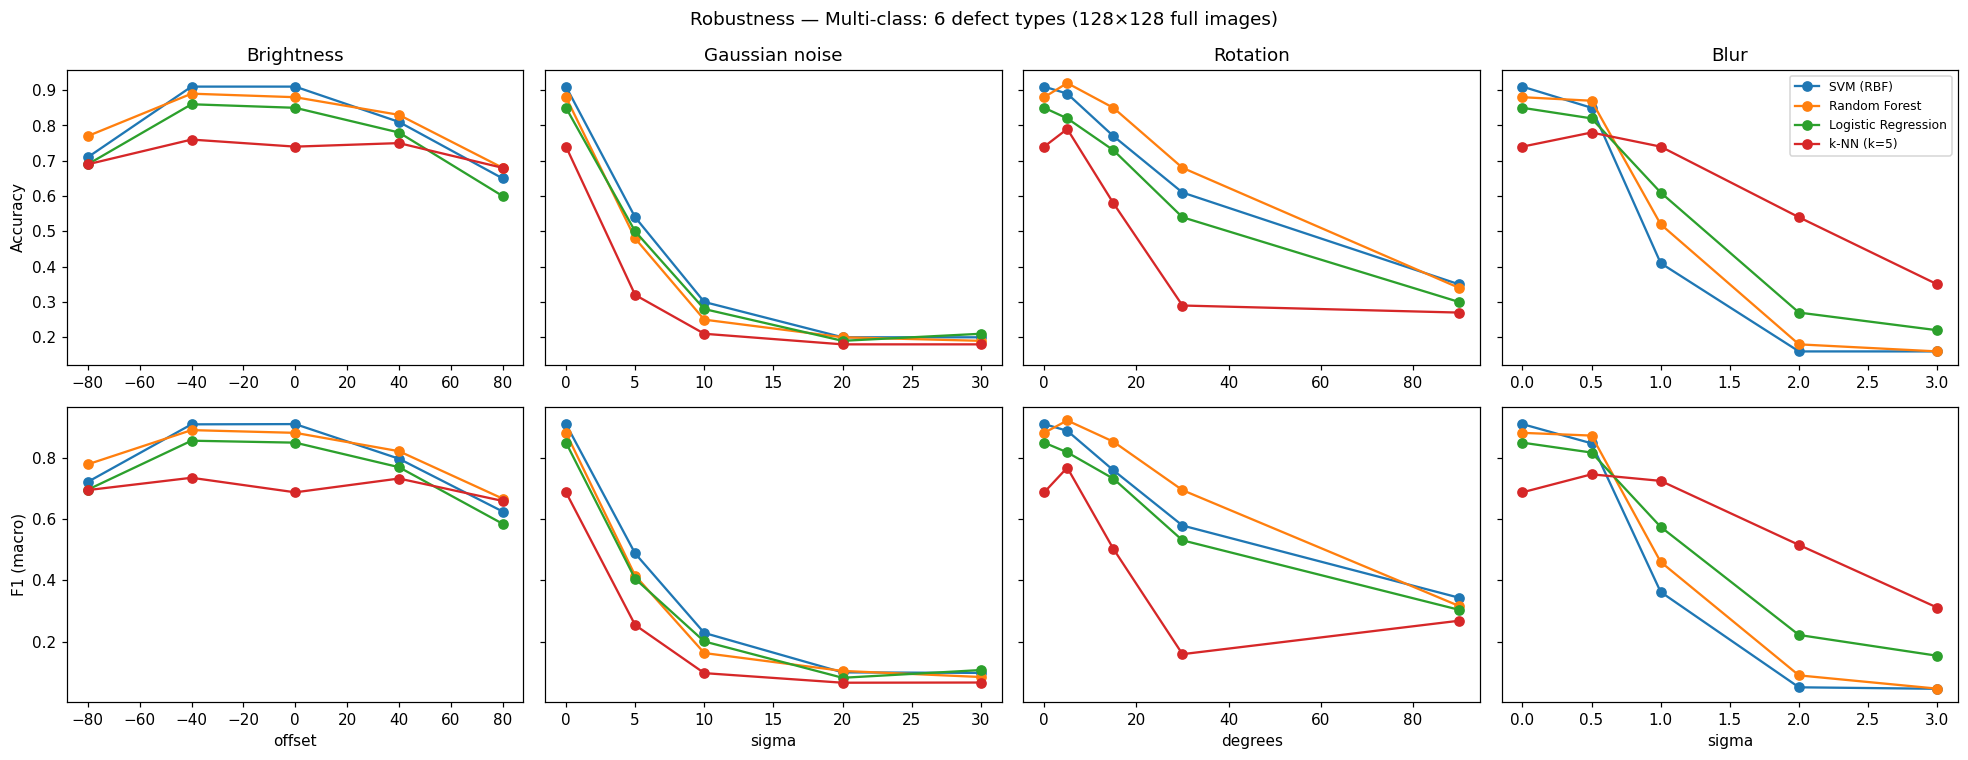

Largest drop vs clean (Δ accuracy / Δ F1) — Multi-class: 6 defect types (128×128 full images)


d_accuracy                                     \
model          Logistic Regression Random Forest SVM (RBF) k-NN (k=5)   
condition                                                               
Blur                         -0.63         -0.72     -0.75      -0.39   
Brightness                   -0.25         -0.20     -0.26      -0.06   
Gaussian noise               -0.66         -0.69     -0.71      -0.56   
Rotation                     -0.55         -0.54     -0.56      -0.47   

                              d_f1                                     
model          Logistic Regression Random Forest SVM (RBF) k-NN (k=5)  
condition                                                              
Blur                        -0.695        -0.834    -0.863     -0.376  
Brightness                  -0.265        -0.215    -0.285     -0.028  
Gaussian noise              -0.767        -0.796    -0.812     -0.621  
Rotation                    -0.545        -0.565    -0.566     -0.528

In [ ]:
for k, R in ROB.items():
    fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey="row")
    clean = R[R.condition == "Clean"].set_index("model")
    for j, (pn, (unit, levels, _)) in enumerate(PERTURB.items()):
        sub = R[R.condition == pn]
        for name in MODELS[k]:
            s = sub[sub.model == name]
            x = [0] + list(s.level) if pn != "Brightness" else sorted([0] + list(s.level))
            for i, met in enumerate(["accuracy", "f1"]):
                yv = dict(zip(s.level, s[met])); yv[0] = clean.loc[name, met]
                axes[i, j].plot(x, [yv[v] for v in x], "o-", label=name)
        axes[0, j].set_title(pn); axes[1, j].set_xlabel(unit)
    axes[0, 0].set_ylabel("Accuracy"); axes[1, 0].set_ylabel("F1" + (" (defective)" if k == "binary" else " (macro)"))
    axes[0, -1].legend(fontsize=8)
    plt.suptitle(f"Robustness — {TASKS[k]['title']}"); plt.tight_layout(); save_fig(f"12_robustness_{k}"); plt.show()

    # compact Δ table: worst-level change per condition
    worst = (R[R.condition != "Clean"].groupby(["condition", "model"])[["d_accuracy", "d_f1"]].min()
             .unstack("model").round(3))
    print(f"Largest drop vs clean (Δ accuracy / Δ F1) — {TASKS[k]['title']}"); display(worst)

### 10b. Mitigation: degradation-aware training (binary inspector)
A deployment-minded experiment: augment the training patches with random brightness, noise, rotation and blur, retrain
the SVM, and repeat the robustness test. This shows how much of the degradation is a *data* problem rather than a
limitation of HOG itself.

Augmented SVM, C = 1


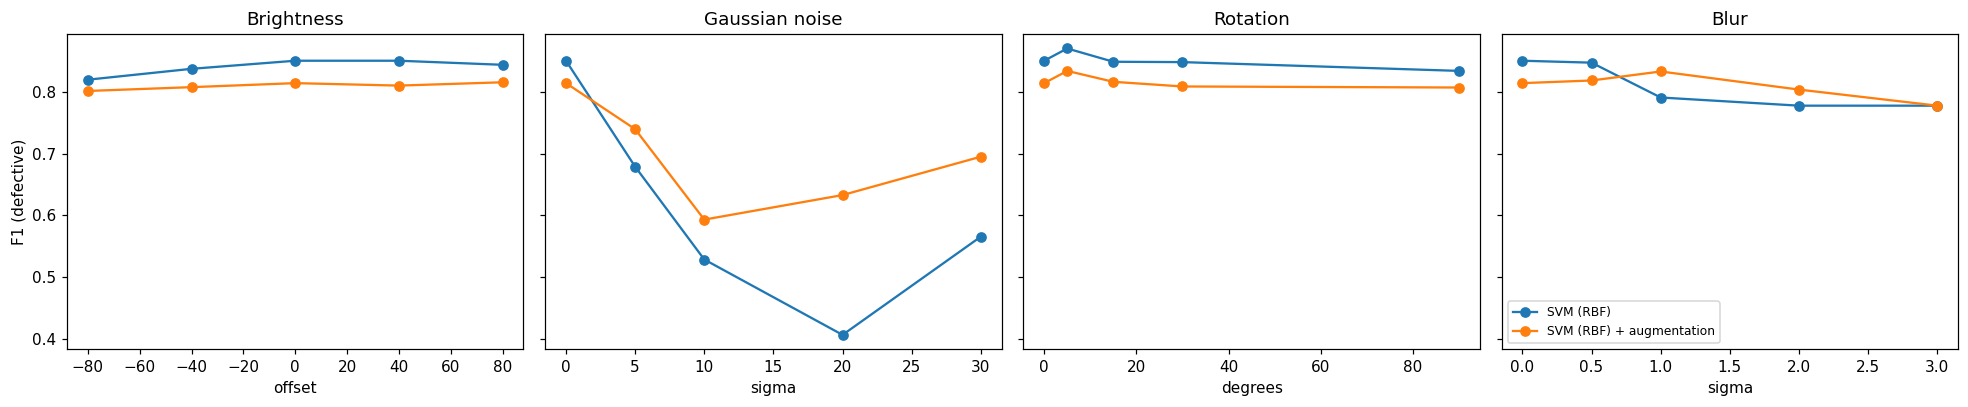

model                 SVM (RBF)  SVM (RBF) + augmentation
condition      level                                     
Blur            0.5      0.8480                    0.8191
                1.0      0.7915                    0.8337
                2.0      0.7782                    0.8043
                3.0      0.7782                    0.7782
Brightness     -80.0     0.8204                    0.8021
               -40.0     0.8380                    0.8083
                40.0     0.8512                    0.8108
                80.0     0.8446                    0.8162
Clean           0.0      0.8512                    0.8148
Gaussian noise  5.0      0.6792                    0.7401
                10.0     0.5286                    0.5933
                20.0     0.4062                    0.6332
                30.0     0.5657                    0.6954
Rotation        5.0      0.8710                    0.8346
                15.0     0.8495                    0.8170
                30.0     0.8489                    0.8094
                90.0     0.8347                    0.8077

In [ ]:
def random_degrade(im, r):
    im = brightness(im, int(r.integers(-60, 61)))
    if r.random() < 0.5: im = noise(im, float(r.uniform(0, 20)), seed=int(r.integers(1e9)))
    if r.random() < 0.5: im = rotate(im, float(r.uniform(-30, 30)))
    if r.random() < 0.5: im = blur(im, float(r.uniform(0.3, 2.0)))
    return im

t, hp = TASKS["binary"], BEST_HOG["binary"]
r = np.random.default_rng(SEED)
X_aug = np.concatenate([t["Xtr"], np.stack([random_degrade(x, r) for x in t["Xtr"]])])
F_aug = hog_batch(X_aug, **hp)
y_aug = np.concatenate([t["ytr"], t["ytr"]]); g_aug = np.concatenate([t["gtr"], t["gtr"]])
svm_aug, info = fit_svm(F_aug, y_aug, g_aug)
print("Augmented SVM, C =", info["C"])

R_aug = robustness("binary", {"SVM (RBF)": MODELS["binary"]["SVM (RBF)"], "SVM (RBF) + augmentation": svm_aug})
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for a, (pn, (unit, levels, _)) in zip(axes, PERTURB.items()):
    for name in R_aug.model.unique():
        s = R_aug[(R_aug.model == name) & R_aug.condition.isin(["Clean", pn])].sort_values("level")
        a.plot(s.level, s.f1, "o-", label=name)
    a.set_title(pn); a.set_xlabel(unit)
axes[0].set_ylabel("F1 (defective)"); axes[-1].legend(fontsize=8)
plt.tight_layout(); save_fig("13_robustness_mitigation"); plt.show()
display(R_aug.pivot_table(index=["condition", "level"], columns="model", values="f1").round(4))

## 11. Industrial quality-control decision module (Task 13)
`SteelQualityInspector` slides the HOG + SVM patch classifier over the whole product surface (64×64 windows,
stride 32), builds a defect-probability map, and **rejects** the product if any window exceeds the recall-targeted
threshold. If rejected, the multi-class model names the most likely defect type.

In [ ]:
class SteelQualityInspector:
    def __init__(self, patch_model, patch_hog, threshold=0.5, patch=PATCH, stride=STRIDE,
                 type_model=None, type_hog=None, type_size=IMG_SIZE, type_names=CLASSES):
        self.m, self.hp, self.th, self.P, self.S = patch_model, patch_hog, threshold, patch, stride
        self.tm, self.thp, self.tsize, self.tnames = type_model, type_hog, type_size, type_names

    def _starts(self, n):
        s = list(range(0, n - self.P + 1, self.S))
        if s[-1] != n - self.P: s.append(n - self.P)
        return s

    def inspect(self, image):
        t0 = time.perf_counter()
        g = preprocess(image)
        if min(g.shape) < self.P:
            g = cv2.resize(g, (max(self.P, g.shape[1]), max(self.P, g.shape[0])))
        H, W = g.shape
        coords = [(y, x) for y in self._starts(H) for x in self._starts(W)]
        F = hog_batch([g[y:y+self.P, x:x+self.P] for y, x in coords], **self.hp)
        p = self.m.predict_proba(F)[:, 1]
        heat, cnt = np.zeros((H, W)), np.zeros((H, W))
        for (y, x), pi in zip(coords, p):
            heat[y:y+self.P, x:x+self.P] += pi; cnt[y:y+self.P, x:x+self.P] += 1
        heat /= np.maximum(cnt, 1)
        i = int(p.argmax()); pmax = float(p[i]); defective = pmax >= self.th
        res = dict(prediction="DEFECTIVE" if defective else "NON-DEFECTIVE",
                   confidence=pmax if defective else 1 - pmax,
                   action="REJECT PRODUCT" if defective else "ACCEPT PRODUCT",
                   defect_prob=pmax, worst_window=(coords[i][1], coords[i][0], self.P, self.P),
                   heatmap=heat, n_windows=len(coords), gray=g)
        if defective and self.tm is not None:
            pt = self.tm.predict_proba(hog_batch([preprocess(g, self.tsize)], **self.thp))[0]
            res["defect_type"], res["type_confidence"] = self.tnames[int(pt.argmax())], float(pt.max())
        res["latency_ms"] = (time.perf_counter() - t0) * 1e3
        return res

    @staticmethod
    def report(r):
        print("=" * 34); print("PRODUCT INSPECTION RESULT"); print("=" * 34)
        print(f"Prediction: {r['prediction']}")
        print(f"Confidence: {r['confidence']*100:.1f}%")
        print(f"Action: {r['action']}")
        if "defect_type" in r:
            print(f"Defect type: {r['defect_type']} ({r['type_confidence']*100:.1f}%)")
        print(f"[windows scanned: {r['n_windows']}, latency: {r['latency_ms']:.1f} ms]")

    def show(self, r, title=""):
        fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.6))
        ax[0].imshow(r["gray"], cmap="gray"); ax[0].set_title(title, fontsize=9)
        ax[1].imshow(r["gray"], cmap="gray"); hm = ax[1].imshow(r["heatmap"], cmap="jet", alpha=0.45, vmin=0, vmax=1)
        if r["prediction"] == "DEFECTIVE":
            x, y, w, h = r["worst_window"]
            ax[1].add_patch(mpatches.Rectangle((x, y), w, h, fill=False, ec="red", lw=2))
        col = "red" if r["prediction"] == "DEFECTIVE" else "green"
        ax[1].set_title(f"{r['prediction']} ({r['confidence']*100:.0f}%) → {r['action'].split()[0]}", color=col, fontsize=10)
        for a in ax: a.axis("off")
        plt.colorbar(hm, ax=ax[1], fraction=0.046, label="P(defect)"); plt.tight_layout(); plt.show()

inspector = SteelQualityInspector(MODELS["binary"]["SVM (RBF)"], BEST_HOG["binary"], threshold=THRESHOLD,
                                  type_model=MODELS["multiclass"]["SVM (RBF)"], type_hog=BEST_HOG["multiclass"])

PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 91.9%
Action: REJECT PRODUCT
Defect type: scratches (98.7%)
[windows scanned: 36, latency: 216.7 ms]


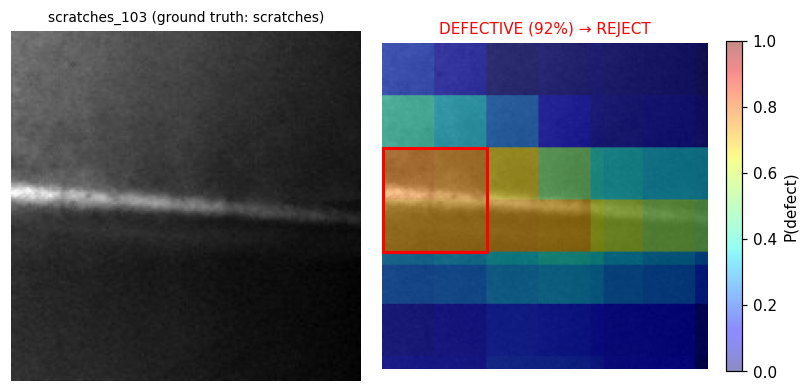

PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 96.9%
Action: REJECT PRODUCT
Defect type: inclusion (87.6%)
[windows scanned: 36, latency: 226.1 ms]


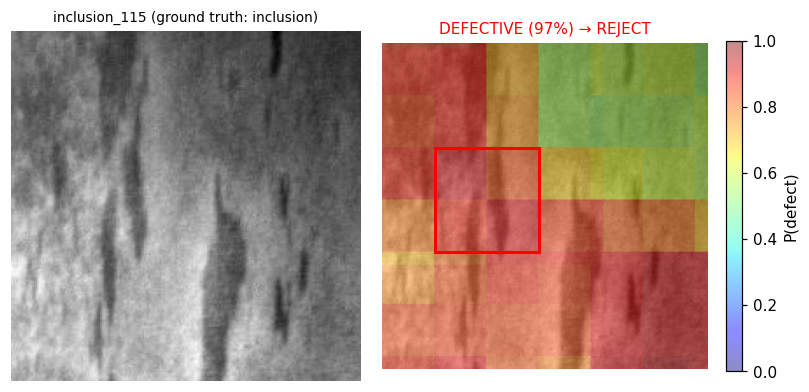

PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 98.8%
Action: REJECT PRODUCT
Defect type: patches (94.8%)
[windows scanned: 36, latency: 213.6 ms]


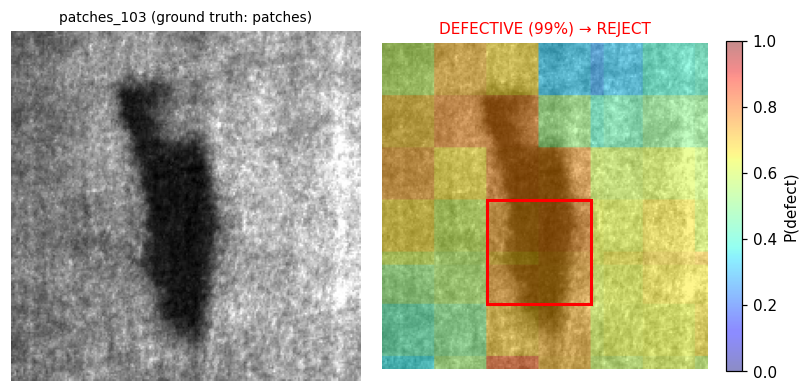

PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 44.4%
Action: REJECT PRODUCT
Defect type: pitted_surface (74.6%)
[windows scanned: 1, latency: 16.9 ms]


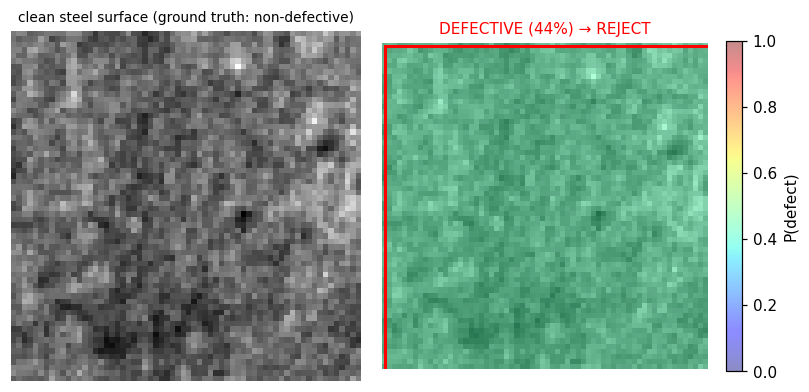

PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 83.6%
Action: REJECT PRODUCT
Defect type: patches (60.2%)
[windows scanned: 1, latency: 19.5 ms]


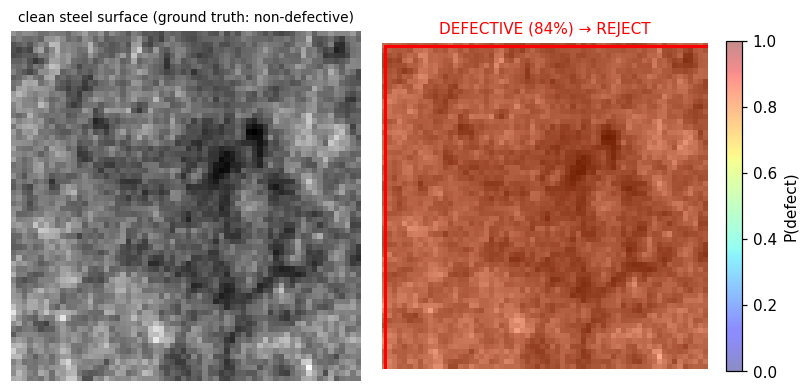

In [ ]:
# ---- demo: full validation products (all contain a defect) and clean surface samples
for c in ["scratches", "inclusion", "patches"]:
    row = va[va.label == c].iloc[0]
    res = inspector.inspect(cv2.imread(row.path)); inspector.report(res)
    inspector.show(res, title=f"{row.stem} (ground truth: {c})")

for i in np.where(TASKS["binary"]["yva"] == 0)[0][:2]:
    res = inspector.inspect(TASKS["binary"]["Xva"][i]); inspector.report(res)
    inspector.show(res, title="clean steel surface (ground truth: non-defective)")

In [ ]:
# ---- system-level evaluation of the decision module
img_res = [inspector.inspect(load_gray(p)) for p in va.path]
reject_rate = np.mean([r["prediction"] == "DEFECTIVE" for r in img_res])
type_acc = np.mean([r.get("defect_type") == l for r, l in zip(img_res, va.label) if "defect_type" in r])
lat = np.array([r["latency_ms"] for r in img_res])

clean_idx = np.where(TASKS["binary"]["yva"] == 0)[0]
false_reject = np.mean([inspector.inspect(TASKS["binary"]["Xva"][i])["prediction"] == "DEFECTIVE" for i in clean_idx])

QC = pd.Series({
    "Defective products correctly REJECTED (image-level recall)": reject_rate,
    "Defect-type accuracy on rejected products": type_acc,
    "Clean surface samples wrongly REJECTED (false-reject rate)": false_reject,
    "Mean latency per product (ms)": lat.mean(),
    "Throughput (products / s, single core)": 1000 / lat.mean(),
}).round(4)
display(QC.to_frame("value")); QC.to_csv(f"{OUT_DIR}/qc_module_evaluation.csv")
print("Note: NEU-DET has no fully defect-free full-size images, so image-level false rejects are measured on "
      "held-out clean 64×64 surface regions.")

,value
Defective products correctly REJECTED (image-level recall),1.0000
Defect-type accuracy on rejected products,0.9100
Clean surface samples wrongly REJECTED (false-reject rate),0.5472
Mean latency per product (ms),228.1794
"Throughput (products / s, single core)",4.3825


Note: NEU-DET has no fully defect-free full-size images, so image-level false rejects are measured on held-out clean 64×64 surface regions.


## 12. Save models, tables and figures

In [ ]:
joblib.dump(dict(patch_model=MODELS["binary"]["SVM (RBF)"], patch_hog=BEST_HOG["binary"], threshold=THRESHOLD,
                 patch=PATCH, stride=STRIDE, type_model=MODELS["multiclass"]["SVM (RBF)"],
                 type_hog=BEST_HOG["multiclass"], type_size=IMG_SIZE, classes=CLASSES),
            f"{OUT_DIR}/steel_inspector.joblib", compress=3)
with open(f"{OUT_DIR}/summary.json", "w") as f:
    json.dump(dict(best_hog=BEST_HOG, threshold=THRESHOLD,
                   results={k: v.round(4).to_dict() for k, v in RESULTS.items()},
                   qc=QC.to_dict()), f, indent=2)
shutil.make_archive("/content/lab05_outputs" if IN_COLAB else "lab05_outputs", "zip", OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))
if IN_COLAB:
    from google.colab import files; files.download("/content/lab05_outputs.zip")

['01_dataset_stats.png', '02_samples.png', '03_binary_patches.png', '04_hog_per_class.png', '05_hog_params_visual.png', '06_hog_patches.png', '07_hog_param_heatmap.png', '08_classifier_comparison.png', '09_confusion_binary.png', '09_confusion_multiclass.png', '10_pr_curve.png', '11_perturbation_examples.png', '12_robustness_binary.png', '12_robustness_multiclass.png', '13_robustness_mitigation.png', 'classifier_comparison_binary.csv', 'classifier_comparison_multiclass.csv', 'hog_param_study_binary.csv', 'hog_param_study_multiclass.csv', 'qc_module_evaluation.csv', 'robustness_binary.csv', 'robustness_multiclass.csv', 'steel_inspector.joblib', 'summary.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Bonus — real-time prototype
Three options, from most to least reproducible:

* **13a. Simulated conveyor stream** — held-out validation surfaces pass the camera one after another with motion
  jitter and sensor noise; every frame is converted to HOG and classified live (PASS / DEFECTIVE overlay, FPS counter).
  Saved as an MP4 you can put in your report / presentation.
* **13b. Live webcam in Colab** — browser webcam frames are streamed into the same pipeline.
* **13c. Local real-time script** — `realtime_inspector.py` for your laptop webcam via OpenCV (true real-time).

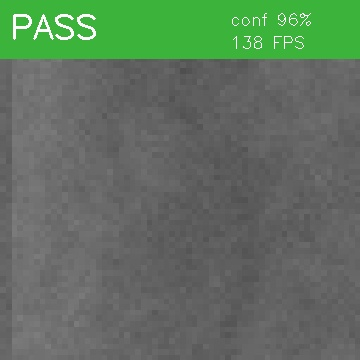

,truth,decision,defective_frames
item,,,
1,DEFECTIVE,DEFECTIVE,10/10
2,PASS,PASS,4/10
3,DEFECTIVE,DEFECTIVE,10/10
4,PASS,PASS,2/10
5,DEFECTIVE,DEFECTIVE,10/10
6,DEFECTIVE,PASS,3/10
7,DEFECTIVE,DEFECTIVE,10/10
8,PASS,DEFECTIVE,9/10
9,DEFECTIVE,DEFECTIVE,5/10


Conveyor accuracy: 9/12


In [ ]:
from IPython.display import display, HTML, Image as IPImage
import base64, subprocess

def overlay(frame_gray, r, fps=None, roi=None, size=360):
    vis = cv2.cvtColor(cv2.resize(frame_gray, (size, size), interpolation=cv2.INTER_NEAREST), cv2.COLOR_GRAY2BGR)
    sx, sy = size / frame_gray.shape[1], size / frame_gray.shape[0]
    ok = r["prediction"] == "NON-DEFECTIVE"; col = (60, 180, 60) if ok else (40, 40, 220)
    if not ok:
        x, y, w, h = r["worst_window"]
        cv2.rectangle(vis, (int(x*sx), int(y*sy)), (int((x+w)*sx), int((y+h)*sy)), col, 2)
    cv2.rectangle(vis, (0, 0), (size, 58), col, -1)
    cv2.putText(vis, "PASS" if ok else "DEFECTIVE", (10, 38), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255, 255, 255), 2)
    cv2.putText(vis, f"conf {r['confidence']*100:.0f}%", (size - 130, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255,255,255), 1)
    if fps: cv2.putText(vis, f"{fps:.0f} FPS", (size - 130, 48), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255,255,255), 1)
    return vis

# ---- 13a: simulated conveyor
tb = TASKS["binary"]; r = np.random.default_rng(7)
items = list(r.choice(np.where(tb["yva"] == 0)[0], 6, replace=False)) + \
        list(r.choice(np.where(tb["yva"] == 1)[0], 6, replace=False))
r.shuffle(items)
FRAMES_PER_ITEM, out_raw, out_mp4 = 10, f"{OUT_DIR}/conveyor_raw.avi", f"{OUT_DIR}/conveyor_demo.mp4"
writer = cv2.VideoWriter(out_raw, cv2.VideoWriter_fourcc(*"MJPG"), 10, (360, 360))
handle = display(None, display_id=True)
log, correct = [], 0
for n, i in enumerate(items):
    votes = []
    for f in range(FRAMES_PER_ITEM):
        frame = rotate(tb["Xva"][i], float(r.normal(0, 2)))                 # mis-alignment jitter
        frame = np.roll(frame, (int(r.integers(-3, 4)), int(r.integers(-3, 4))), axis=(0, 1))
        frame = noise(frame, 3, seed=int(r.integers(1e9)))                 # sensor noise
        t0 = time.perf_counter(); res = inspector.inspect(frame); fps = 1 / (time.perf_counter() - t0)
        vis = overlay(res["gray"], res, fps); writer.write(vis); votes.append(res["prediction"] == "DEFECTIVE")
        if f % 3 == 0:
            handle.update(IPImage(data=cv2.imencode(".jpg", vis)[1].tobytes()))
    decision = "DEFECTIVE" if np.mean(votes) >= 0.5 else "PASS"
    truth = "DEFECTIVE" if tb["yva"][i] == 1 else "PASS"; correct += decision == truth
    log.append(dict(item=n + 1, truth=truth, decision=decision, defective_frames=f"{sum(votes)}/{len(votes)}"))
writer.release()
display(pd.DataFrame(log).set_index("item")); print(f"Conveyor accuracy: {correct}/{len(items)}")

if shutil.which("ffmpeg"):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", out_raw, "-vcodec", "libx264",
                    "-pix_fmt", "yuv420p", out_mp4], check=True)
    b64 = base64.b64encode(open(out_mp4, "rb").read()).decode()
    display(HTML(f'<video width=360 controls autoplay loop muted src="data:video/mp4;base64,{b64}"></video>'))

### 13b. Live webcam (Colab)
Allow camera access when the browser asks. The centre square of each frame is inspected. A webcam will not see steel,
so for a convincing demo hold up a NEU image on your phone screen, or a metal surface with a scratch.

In [ ]:
N_FRAMES = 150   # ~ how long the live loop runs

if IN_COLAB:
    from google.colab.output import eval_js
    from IPython.display import Javascript
    display(Javascript('''
      window.lab05Start = async function() {
        if (window.lab05Video) return true;
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        const v = document.createElement('video'); v.style.display = 'none';
        document.body.appendChild(v); v.srcObject = stream; await v.play();
        window.lab05Video = v; window.lab05Stream = stream; return true;
      };
      window.lab05Grab = async function(q) {
        await window.lab05Start(); const v = window.lab05Video;
        const c = document.createElement('canvas'); c.width = v.videoWidth; c.height = v.videoHeight;
        c.getContext('2d').drawImage(v, 0, 0); return c.toDataURL('image/jpeg', q);
      };
      window.lab05Stop = function() {
        if (window.lab05Stream) window.lab05Stream.getTracks().forEach(t => t.stop());
        if (window.lab05Video) window.lab05Video.remove();
        window.lab05Video = null; window.lab05Stream = null; return true;
      };'''))
    live = display(None, display_id=True)
    try:
        for _ in range(N_FRAMES):
            data = eval_js("lab05Grab(0.7)")
            frame = cv2.imdecode(np.frombuffer(base64.b64decode(data.split(",")[1]), np.uint8), cv2.IMREAD_COLOR)
            h, w = frame.shape[:2]; s = min(h, w)
            roi = frame[(h - s)//2:(h + s)//2, (w - s)//2:(w + s)//2]
            roi = preprocess(roi, 200)                                 # match NEU acquisition scale (200×200)
            t0 = time.perf_counter(); res = inspector.inspect(roi); fps = 1 / (time.perf_counter() - t0)
            live.update(IPImage(data=cv2.imencode(".jpg", overlay(res["gray"], res, fps))[1].tobytes()))
    finally:
        eval_js("lab05Stop()")
else:
    print("Not running in Colab – use the local script in 13c for webcam inference.")

<IPython.core.display.Javascript object>

None

### 13c. Local real-time script (true real-time on your laptop)
Download `steel_inspector.joblib` and `realtime_inspector.py` from the outputs zip, put them in one folder, then:
```bash
pip install opencv-python scikit-image scikit-learn joblib
python realtime_inspector.py            # webcam 0
python realtime_inspector.py video.mp4  # or a video file
```
Press **q** to quit.

In [ ]:
%%writefile {OUT_DIR}/realtime_inspector.py
"""Real-time HOG + SVM steel surface inspector (Lab 05 bonus). Usage: python realtime_inspector.py [source]"""
import sys, time, cv2, joblib, numpy as np
from skimage.feature import hog

cfg = joblib.load("steel_inspector.joblib")
P, S, TH, HP = cfg["patch"], cfg["stride"], cfg["threshold"], cfg["patch_hog"]

def feats(p):
    return hog(p, orientations=HP["orient"], pixels_per_cell=(HP["ppc"],) * 2,
               cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)

def starts(n):
    s = list(range(0, n - P + 1, S))
    return s if s[-1] == n - P else s + [n - P]

src = sys.argv[1] if len(sys.argv) > 1 else 0
cap = cv2.VideoCapture(int(src) if str(src).isdigit() else src)
while True:
    ok, frame = cap.read()
    if not ok: break
    t0 = time.perf_counter()
    h, w = frame.shape[:2]; s = min(h, w)
    roi = cv2.cvtColor(frame[(h - s)//2:(h + s)//2, (w - s)//2:(w + s)//2], cv2.COLOR_BGR2GRAY)
    roi = cv2.resize(roi, (200, 200), interpolation=cv2.INTER_AREA)
    coords = [(y, x) for y in starts(200) for x in starts(200)]
    pr = cfg["patch_model"].predict_proba(np.stack([feats(roi[y:y+P, x:x+P]) for y, x in coords]))[:, 1]
    i = int(pr.argmax()); bad = pr[i] >= TH; conf = pr[i] if bad else 1 - pr[i]
    fps = 1 / (time.perf_counter() - t0)
    col = (40, 40, 220) if bad else (60, 180, 60)
    x0, y0 = (w - s) // 2, (h - s) // 2; k = s / 200
    cv2.rectangle(frame, (x0, y0), (x0 + s, y0 + s), (255, 255, 255), 1)
    if bad:
        y, x = coords[i]
        cv2.rectangle(frame, (x0 + int(x*k), y0 + int(y*k)), (x0 + int((x+P)*k), y0 + int((y+P)*k)), col, 2)
    cv2.rectangle(frame, (0, 0), (w, 50), col, -1)
    cv2.putText(frame, f"{'DEFECTIVE' if bad else 'PASS'}  {conf*100:.0f}%   {fps:.0f} FPS",
                (10, 35), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2)
    cv2.imshow("Steel surface inspection (q to quit)", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"): break
cap.release(); cv2.destroyAllWindows()

## 14. Numbers for your report
Run this last — it prints every figure/table you need, mapped to the report sections.

In [ ]:
print("Best HOG configuration:", BEST_HOG)
print(f"Recall-targeted threshold: {THRESHOLD:.3f}\n")
for k in TASKS:
    print("##", TASKS[k]["title"]); display(RESULTS[k][["accuracy", "precision", "recall", "f1", "infer_ms_per_img"]].round(4))
display(QC.to_frame("QC module"))
print("\nFigures in", OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    if f.endswith(".png"): print("  ", f)
print('''
Report mapping:
  3 Dataset Description      -> 01_dataset_stats, 02_samples, 03_binary_patches
  4 Preprocessing            -> section 4 cell
  5 HOG Feature Extraction   -> 04/05/06_hog_*
  7 Experimental Setup       -> 07_hog_param_heatmap + hog_param_study_*.csv
  8 Results                  -> 08_classifier_comparison, 09_confusion_*, 10_pr_curve, classifier_comparison_*.csv
  9 Robustness Analysis      -> 11/12/13_*, robustness_*.csv
  10 Deployment Discussion   -> qc_module_evaluation.csv, conveyor_demo.mp4, latency/throughput numbers
''')
# re-zip so the bonus video and real-time script are included
shutil.make_archive("/content/lab05_outputs" if IN_COLAB else "lab05_outputs", "zip", OUT_DIR)
if IN_COLAB:
    from google.colab import files; files.download("/content/lab05_outputs.zip")